# KDnuggets 1년치 기사로 본 AI·데이터 기술 트렌드

AI·데이터 전문 매체 **KDnuggets**에 최근 1년 동안 올라온 기사를 직접 수집하고, 탐색적 데이터 분석(EDA)으로 AI·데이터 기술 트렌드를 파악합니다.
생성형 AI뿐 아니라 데이터 엔지니어링·분석, ML·운영까지 함께 보고, 1년 사이 어떤 주제가 떠오르고 식었는지 확인합니다.

**실행 방법:** 위에서부터 순서대로 실행하면 됩니다. 별도의 데이터 파일 없이, 노트북이 **실행 시점 기준 최근 1년의 기사를 직접 수집**해서 분석합니다.
그래서 실행할 때마다 기간과 결과 숫자가 달라질 수 있습니다. 숫자는 모두 코드로 계산해 출력하고, 마크다운에는 결과를 읽는 방법을 적었습니다.
리포트를 쓴 시점의 결과를 그대로 재현하려면 0.2의 `LOAD_CSV`에 저장된 스냅샷 파일을 지정하세요.

| 순서 | 내용 |
|---|---|
| 0 | 환경 설정 및 데이터 수집 |
| 1 | 분석 개요 |
| 2 | 데이터 이해와 품질 점검 |
| 3 | 전처리 |
| 4 | 기본 분포 (단변량) |
| 5 | 주제 분류 (규칙 기반) |
| 6 | 키워드 분석 (빈도 기반) |
| 7 | 시간에 따른 변화 |
| 8 | 변수 간 관계 |
| 9 | 결론과 한계 |

# 0. 환경 설정 및 데이터 수집

### 0.1 라이브러리와 한글 폰트

In [1]:
# ─────────────────────────────────────────────
# 환경 준비 — 라이브러리 + 한글 폰트
# ─────────────────────────────────────────────
# 필요 시 아래 주석을 해제해 설치하세요.
# !pip install numpy pandas matplotlib seaborn missingno requests beautifulsoup4 -q

import html
import re
import time
import urllib.robotparser
import warnings
import xml.etree.ElementTree as ET
from collections import Counter
from math import erf, sqrt
from datetime import datetime, timedelta, timezone
from email.utils import parsedate_to_datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno   # 결측 패턴 시각화 전용 라이브러리 (2장에서 사용)
import requests
from bs4 import BeautifulSoup
from matplotlib import font_manager

warnings.filterwarnings("ignore")

# seaborn 스타일은 폰트 설정보다 먼저 (나중에 쓰면 한글 폰트가 초기화됨)
sns.set_style("whitegrid")

# 한글 폰트: 설치된 폰트 중 첫 번째를 사용 (macOS → Windows → Colab·Linux 순)
KOREAN_FONTS = ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]
installed = {f.name for f in font_manager.fontManager.ttflist}
font = next((name for name in KOREAN_FONTS if name in installed), None)
if font:
    plt.rcParams["font.family"] = [font, "DejaVu Sans"]   # 한글 폰트에 없는 글자(é, á 등)는 DejaVu Sans로 표시
else:
    print("한글 폰트를 찾지 못했어요. Colab이라면 !apt-get -qq install fonts-nanum 실행 후 런타임을 재시작하세요.")

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_colwidth", 100)

print("준비 완료! 라이브러리 버전을 확인합니다.")
print("한글 폰트:", font)
print("numpy :", np.__version__)
print("pandas:", pd.__version__)

준비 완료! 라이브러리 버전을 확인합니다.
한글 폰트: AppleGothic
numpy : 2.0.1
pandas: 3.0.6


### 0.2 수집·분석 설정

값을 바꾸고 싶으면 이 셀만 수정하면 됩니다.

- `PERIOD_DAYS`: 실행 시점부터 며칠 전까지의 기사를 수집할지 정합니다. 기본값 365는 **딱 1년치**입니다. 트렌드는 "변화"이므로 한 계절만 보면 출렁임과 구분이 안 되어, 1년을 기본으로 잡았습니다.
- `SAVE_CSV`: 수집한 원본을 CSV로 남깁니다. 이 노트북은 실행할 때마다 최신 기사를 새로 수집하므로, 리포트를 쓴 시점의 데이터를 다시 보려면 스냅샷이 필요합니다.
- `LOAD_CSV`: 저장해 둔 CSV 경로를 넣으면 새로 수집하지 않고 그 파일로 분석합니다. 9.2의 해석과 같은 숫자를 재현하려면 리포트 작성에 쓴 CSV를 지정하세요.
- `EXCLUDE_PARTNERS`: 협찬 글(`Partners` 태그)을 트렌드 분석에서 뺄지 정합니다. 협찬 글은 매체의 광고 사정을 반영하기 때문입니다.

In [2]:
# ── 수집 설정 ──
BASE = "https://www.kdnuggets.com"
HEADERS = {"User-Agent": "Mozilla/5.0 (personal study project)"}
DELAY = 1.0          # 요청 간 대기(초) - 서버 부담 줄이기
PERIOD_DAYS = 365    # 실행 시점부터 거슬러 올라가 수집할 기간(일) → 1년치
PER_PAGE = 50
MAX_PAGES = 30       # 안전장치: 최대 요청 페이지 수 (1년치는 보통 12~13페이지)
SAVE_CSV = True      # 수집 원본을 CSV 스냅샷으로 저장
LOAD_CSV = None      # 예: "kdnuggets_articles_365d_20261029.csv" → 새로 수집하지 않고 이 파일로 분석
COLUMNS = ["title", "url", "summary", "author", "published", "category", "tags", "collected_at"]

# 수집 시작 시점 (UTC, 실행 시각 기준 PERIOD_DAYS일 전)
SINCE = datetime.now(timezone.utc).replace(tzinfo=None) - timedelta(days=PERIOD_DAYS)

# ── 분석 설정 ──
EXCLUDE_PARTNERS = True   # 협찬 글(Partners 태그)을 트렌드 분석에서 제외
MIN_MONTH_N = 20          # 기사가 이보다 적은 달(수집 기간 첫 달처럼 며칠만 걸친 달)은 이웃 달과 묶어서 집계

### 0.3 수집기

| 항목 | 내용 |
|---|---|
| 출처 | KDnuggets 사이트 전체 게시글 (블로그·튜토리얼·뉴스 등 특정 섹션에 한정하지 않음) |
| 기간 | 실행 시점부터 `PERIOD_DAYS`일 전까지 (기본 365일). API의 `after` 조건으로 기간 안의 글만 요청합니다. |
| 수집 방식 ① | **WordPress REST API** (`/wp-json/wp/v2/posts`): HTML 대신 사이트가 제공하는 구조화된 JSON을 사용합니다. 페이지 디자인이 바뀌어도 잘 깨지지 않고, 저자·날짜·태그가 필드로 나뉘어 있어 정제가 쉽습니다. |
| 수집 방식 ② | **RSS 피드** (`/feed`): API가 실패할 때만 쓰는 대체 경로입니다. 최신 10~20건만 제공하고 태그를 구분할 수 없습니다. |
| 수집 항목 | 제목, URL, 요약문, 저자, 발행일(UTC), 카테고리, 태그, 수집 시각 |
| 수집 윤리 | robots.txt로 허용 여부를 확인하고, 요청 사이에 1초씩 쉬며, 개인 학습 목적으로만 사용합니다. |

In [3]:
def is_allowed(url: str) -> bool:
    """robots.txt 에서 수집이 허용된 경로인지 확인"""
    rp = urllib.robotparser.RobotFileParser(f"{BASE}/robots.txt")
    try:
        rp.read()
    except Exception:
        return True  # robots.txt 를 못 읽으면 진행 (직접 확인 권장)
    return rp.can_fetch(HEADERS["User-Agent"], url)


def clean_text(raw: str) -> str:
    """HTML 태그·엔티티 제거 후 공백 정리"""
    if not raw:
        return ""
    text = BeautifulSoup(raw, "html.parser").get_text(" ", strip=True)
    text = re.sub(r"\s+", " ", html.unescape(text)).strip()
    return text.replace("The post appeared first on KDnuggets.", "").strip()


def now_str() -> str:
    return datetime.now().strftime("%Y-%m-%d %H:%M:%S")


# ① WordPress REST API ------------------------------------------------------
def collect_via_api() -> list[dict]:
    endpoint = f"{BASE}/wp-json/wp/v2/posts"
    if not is_allowed(endpoint):
        print("robots.txt 에서 API 경로가 허용되지 않아 건너뜁니다.")
        return []

    rows, collected_at = [], now_str()
    for page in range(1, MAX_PAGES + 1):
        try:
            r = requests.get(
                endpoint,
                params={"per_page": PER_PAGE, "page": page, "_embed": 1,
                        "after": SINCE.strftime("%Y-%m-%dT%H:%M:%S")},   # 기간 안의 글만
                headers=HEADERS,
                timeout=20,
            )
        except requests.RequestException as e:
            print(f"API 요청 실패: {e}")
            break
        if r.status_code != 200:        # 마지막 페이지를 넘기면 400 반환
            if page == 1:
                print(f"API 응답 오류: HTTP {r.status_code}")
            break
        posts = r.json()
        if not posts:
            break

        for p in posts:
            emb = p.get("_embedded", {})
            authors = [a.get("name", "") for a in emb.get("author", []) if "name" in a]
            terms = [t for group in emb.get("wp:term", []) for t in group]
            cats = [t.get("name", "") for t in terms if t.get("taxonomy") == "category"]
            tags = [t.get("name", "") for t in terms if t.get("taxonomy") == "post_tag"]
            rows.append({
                "title": clean_text(p["title"]["rendered"]),
                "url": p.get("link", ""),
                "summary": clean_text(p.get("excerpt", {}).get("rendered", "")),
                "author": ", ".join(authors),
                "published": p.get("date_gmt", ""),   # UTC 기준
                "category": ", ".join(cats),
                "tags": ", ".join(tags),
                "collected_at": collected_at,
            })
        print(f"API {page}페이지: {len(posts)}건")
        time.sleep(DELAY)
    return rows


# ② RSS 피드 (대체 경로) ----------------------------------------------------
def collect_via_rss() -> list[dict]:
    feed_url = f"{BASE}/feed"
    try:
        r = requests.get(feed_url, headers=HEADERS, timeout=20)
        r.raise_for_status()
    except requests.RequestException as e:
        print(f"RSS 요청 실패: {e}")
        return []

    ns = {"dc": "http://purl.org/dc/elements/1.1/"}
    root = ET.fromstring(r.content)
    rows, collected_at = [], now_str()
    for item in root.iter("item"):
        pub = item.findtext("pubDate", "")
        try:
            pub = parsedate_to_datetime(pub).astimezone(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S")
        except (TypeError, ValueError):
            pass
        rows.append({
            "title": clean_text(item.findtext("title", "")),
            "url": item.findtext("link", ""),
            "summary": clean_text(item.findtext("description", "")),
            "author": item.findtext("dc:creator", "", ns),
            "published": pub,
            # RSS의 category 에는 카테고리와 태그가 섞여 있음
            "category": ", ".join(c.text for c in item.findall("category") if c.text),
            "tags": "",  # RSS에서는 카테고리와 구분되지 않아 비워 둠
            "collected_at": collected_at,
        })
    return rows


def collect() -> tuple[pd.DataFrame, str]:
    """API로 수집하고, 실패하면 RSS로 대체. (데이터프레임, 수집 경로) 반환"""
    rows, source = collect_via_api(), "REST API"
    if not rows:
        print("API 수집 결과가 없어 RSS 로 전환합니다.")
        rows, source = collect_via_rss(), "RSS"

    df = pd.DataFrame(rows, columns=COLUMNS).drop_duplicates(subset="url")
    df["published"] = pd.to_datetime(df["published"], errors="coerce")
    df["collected_at"] = pd.to_datetime(df["collected_at"])
    df = df[df["published"] >= SINCE]   # API의 after는 사이트 현지 시각 기준이라 UTC로 한 번 더 자름
    df = df.sort_values("published", ascending=False).reset_index(drop=True)
    return df, source

### 0.4 수집 실행

`LOAD_CSV`를 지정했으면 저장된 스냅샷을 읽고, 아니면 새로 수집합니다. 1년치는 요청 12~13번이라 20초 정도 걸립니다.

수집이 실패하면 이 셀에서 바로 멈추도록 확인 문장(`assert`)을 넣었습니다. 이후 셀이 줄줄이 에러 나는 것을 막기 위해서입니다.

In [4]:
if LOAD_CSV:
    # 빈 문자열을 NaN으로 바꾸지 않아야 API로 수집한 데이터와 형태가 같아짐
    df_raw = pd.read_csv(LOAD_CSV, parse_dates=["published", "collected_at"], keep_default_na=False)
    SOURCE = "저장된 CSV"
else:
    df_raw, SOURCE = collect()

assert len(df_raw) > 0, "수집 실패: 인터넷 연결을 확인하세요. 사이트 구조가 바뀌었거나 접근이 차단됐을 수도 있어요."
if SOURCE == "RSS":
    print("[주의] RSS로 대체 수집됐어요. 최신 10~20건뿐이고 태그가 비어 있어 태그·시간 변화 분석은 의미가 약합니다.")

print(f"\n[{SOURCE}] {len(df_raw)}건")
print(f"기간(UTC): {df_raw['published'].min()} ~ {df_raw['published'].max()}")

if SAVE_CSV and not LOAD_CSV:
    fname = f"kdnuggets_articles_{PERIOD_DAYS}d_{datetime.now():%Y%m%d}.csv"
    df_raw.to_csv(fname, index=False, encoding="utf-8-sig")  # 엑셀에서 한글 깨짐 방지
    print(f"스냅샷 저장 → {fname}  (같은 결과를 다시 보려면 LOAD_CSV에 이 이름을 넣으세요)")

df_raw.head()

API 1페이지: 50건


API 2페이지: 50건


API 3페이지: 50건


API 4페이지: 50건


API 5페이지: 50건


...

API 10페이지: 50건


API 11페이지: 50건


API 12페이지: 48건



[REST API] 598건
기간(UTC): 2025-10-29 12:35:44 ~ 2026-10-28 14:00:00
스냅샷 저장 → kdnuggets_articles_365d_20261029.csv  (같은 결과를 다시 보려면 LOAD_CSV에 이 이름을 넣으세요)


,title,url,summary,author,published,category,tags,collected_at
0,Access Multiple AI Models in Your Python Apps Using OpenRouter,https://www.kdnuggets.com/access-multiple-ai-models-in-your-python-apps-using-openrouter,"Learn how to get started with the OpenRouter API to call multiple AI models through one API, com...",Bala Priya C,2026-10-28 14:00:00,Originals,Artificial Intelligence,2026-10-29 15:09:09
1,Can This Open-Source Model Beat AI Detectors? Let’s Test It Locally,https://www.kdnuggets.com/can-this-open-source-model-beat-ai-detectors-lets-test-it-locally,"Can a free, open-source AI humanizer beat paid tools? We tested a 12B model locally and compared...",Abid Ali Awan,2026-10-28 12:00:00,Originals,Artificial Intelligence,2026-10-29 15:09:09
2,Which Local LMs are Best For Which Tasks,https://www.kdnuggets.com/which-local-lms-are-best-for-which-tasks,"A local language model is one whose actual weights, the enormous file of learned numbers that co...",Shittu Olumide,2026-10-28 12:00:00,Originals,Language Models,2026-10-29 15:09:09
3,"Google Gemini Omni: What It Actually Does, What It Costs, and How It Compares",https://www.kdnuggets.com/google-gemini-omni-what-it-actually-does-what-it-costs-and-how-it-comp...,"Gemini Omni is a member of Google's Gemini generative model family, built specifically to create...",Shittu Olumide,2026-10-27 12:00:00,Originals,Artificial Intelligence,2026-10-29 15:09:09
4,The Roadmap to Becoming a Computer Vision Engineer in 2026,https://www.kdnuggets.com/the-roadmap-to-becoming-a-computer-vision-engineer-in-2026,"A four-stage technical roadmap for becoming a computer vision engineer, from spatial mathematics...",Vinod Chugani,2026-10-26 14:00:00,Originals,Artificial Intelligence,2026-10-29 15:09:09


# 1. 분석 개요

**목적:** AI·데이터 실무 매체인 KDnuggets의 최근 1년치 기사로, AI·데이터 기술 가운데 어떤 주제가 떠오르고 어떤 주제가 식었는지 파악합니다.

**분석 질문**
1. 지난 1년 동안 가장 많이 다뤄진 기술 주제는 무엇인가?
2. 생성형 AI와 데이터·ML 기본기의 비중은 1년 사이 어떻게 달라졌는가?
3. 비중이 뚜렷하게 늘거나 줄어든 주제는 무엇인가?
4. 미리 정한 주제 규칙(5장)과 실제 제목에 많이 쓰인 단어(6장)는 같은 결론을 가리키는가?
5. 이 변화는 업계의 흐름인가, 매체(저자) 사정인가?

**분석 방법:** 카테고리·태그가 주제를 잘 구분하는지 먼저 확인하고(2장), 제목과 요약문에 키워드 규칙을 적용한 하향식 분류(5장)와 단어 빈도를 센 상향식 분석(6장)을 서로 교차 확인합니다.
시간 변화는 분기(3개월)와 전반·후반(6개월)으로 나눠 비교하고(7장), 변화가 저자 구성 때문인지 따로 확인합니다(8장).

**왜 1년인가:** 트렌드는 "변화"입니다. 몇 달만 보면 한두 달의 출렁임과 실제 추세를 구분할 수 없어서, 1년을 분기 단위로 나눠 같은 방향으로 꾸준히 움직이는지를 봅니다.

이번 실행에서 수집한 데이터는 다음과 같습니다.

In [5]:
overview = pd.Series({
    "수집 시각": f"{df_raw['collected_at'].iloc[0]:%Y-%m-%d %H:%M}",
    "수집 경로": SOURCE,
    "기사 수": f"{len(df_raw)}건",
    "기간(UTC)": f"{df_raw['published'].min():%Y-%m-%d} ~ {df_raw['published'].max():%Y-%m-%d}",
    "저자 수": f"{df_raw['author'].nunique()}명",
}, name="내용").to_frame()
overview

,내용
수집 시각,2026-10-29 15:09
수집 경로,REST API
기사 수,598건
기간(UTC),2025-10-29 ~ 2026-10-28
저자 수,19명


# 2. 데이터 이해와 품질 점검

### 2.1 구조 확인

In [6]:
print("행, 열:", df_raw.shape)
df_raw.info()

행, 열: (598, 8)
<class 'pandas.DataFrame'>
RangeIndex: 598 entries, 0 to 597
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   title         598 non-null    str           
 1   url           598 non-null    str           
 2   summary       598 non-null    str           
 3   author        598 non-null    str           
 4   published     598 non-null    datetime64[us]
 5   category      598 non-null    str           
 6   tags          598 non-null    str           
 7   collected_at  598 non-null    datetime64[us]
dtypes: datetime64[us](2), str(6)
memory usage: 222.9 KB


### 2.2 결측값

API는 값이 없을 때 결측(NaN) 대신 빈 문자열(`""`)을 주는 경우가 있어서, 빈 문자열도 결측으로 바꿔 점검합니다. 흰 줄이 보이는 컬럼에 결측이 있다는 뜻입니다.

,결측 수,결측 비율(%)
title,0,0.0
url,0,0.0
summary,1,0.2
author,0,0.0
published,0,0.0
category,0,0.0
tags,5,0.8
collected_at,0,0.0


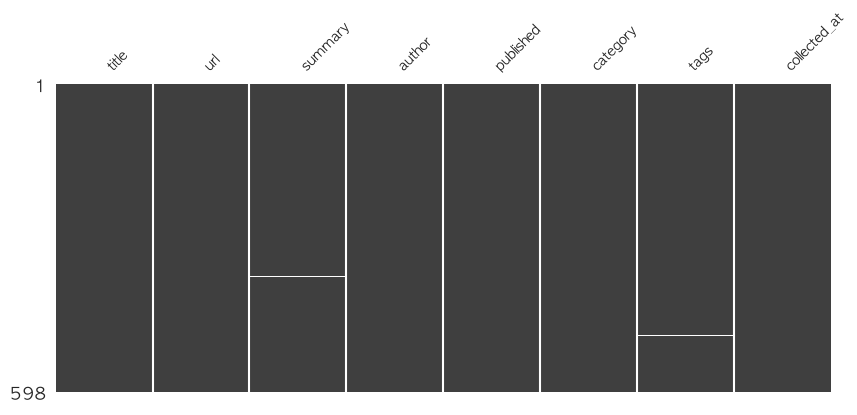

In [7]:
df_check = df_raw.replace("", np.nan)
missing = pd.DataFrame({
    "결측 수": df_check.isna().sum(),
    "결측 비율(%)": (df_check.isna().mean() * 100).round(1),
})
display(missing)

msno.matrix(df_check, figsize=(10, 4), fontsize=10, sparkline=False)
plt.show()

### 2.3 중복값

수집 함수에서 URL 기준 중복은 이미 제거했습니다. 제목이 같은 기사가 따로 있는지도 확인합니다.

In [8]:
print("URL 중복:", df_raw["url"].duplicated().sum(), "건")
print("제목 중복:", df_raw["title"].duplicated().sum(), "건")

URL 중복: 0 건
제목 중복: 0 건


### 2.4 주제 분석에 쓸 수 있는 컬럼인가?

주제를 나타낼 것 같은 컬럼은 `category`와 `tags`입니다. 한 값에 기사가 몰려 있거나 종류가 너무 적으면 주제를 구분하는 데 쓸 수 없습니다.

In [9]:
cat = df_raw["category"].value_counts().rename("기사 수").to_frame()
cat["비중(%)"] = (cat["기사 수"] / len(df_raw) * 100).round(1)

tag_kinds = df_raw["tags"].str.split(", ").explode().replace("", np.nan).dropna().nunique()
print(f"카테고리 종류: {len(cat)}개, 1위 '{cat.index[0]}' 비중: {cat['비중(%)'].iloc[0]}%")
print(f"태그 종류: {tag_kinds}개")
cat

카테고리 종류: 5개, 1위 'Originals' 비중: 90.8%
태그 종류: 15개


,기사 수,비중(%)
category,,
Originals,543,90.8
Products and Services,46,7.7
"Cheat Sheets, Originals",5,0.8
News,2,0.3
"Originals, Products and Services",2,0.3


**읽는 법:** 카테고리 1위 비중이 매우 높으면(예: "Originals"가 90% 이상) 카테고리는 기술 주제가 아니라 "자체 제작 글" 같은 편집 분류라는 뜻입니다. 태그도 종류가 10개 안팎이고 "Artificial Intelligence"처럼 넓은 값이 대부분이면, 에이전트·로컬 모델 같은 구체적인 트렌드를 구분할 수 없습니다.

그래서 이 분석에서는 **제목과 요약문 텍스트로 주제를 직접 분류**합니다(5장). 태그는 전체 분포 확인(4장)과 협찬 글을 걸러내는 용도(3장)로만 사용합니다.

# 3. 전처리

| 작업 | 이유 |
|---|---|
| 발행일 UTC → 한국 시간(KST) | 요일·월 집계를 한국 기준으로 맞추기 위해 |
| 월·요일·전반/후반 컬럼 추가 | 시간에 따른 변화를 보기 위해 |
| 태그를 리스트로 분리, 협찬 글 표시 | 태그 분포를 세고 협찬 글을 거르기 위해 |
| 제목·요약문 단어 수 | 글 형식의 분포를 보기 위해 |
| 제목+요약문 소문자 텍스트 | 주제 분류 규칙을 적용하기 위해 |

In [10]:
df = df_raw.copy()

# 1) 발행일: UTC → 한국 시간(KST)
df["published"] = df["published"].dt.tz_localize("UTC").dt.tz_convert("Asia/Seoul").dt.tz_localize(None)
df["month"] = df["published"].dt.to_period("M").astype(str)
WEEKDAYS = ["월", "화", "수", "목", "금", "토", "일"]
df["weekday"] = df["published"].dt.dayofweek.map(dict(enumerate(WEEKDAYS)))

# 2) 태그를 리스트로 나누고 협찬 글 표시
df["tag_list"] = df["tags"].fillna("").map(lambda s: [t for t in s.split(", ") if t])
df["is_partner"] = df["tag_list"].map(lambda tags: "Partners" in tags)

# 3) 파생 변수: 제목·요약문 단어 수, 주제 분류용 텍스트
df["title_words"] = df["title"].str.split().str.len()
df["summary_words"] = df["summary"].str.split().str.len()
df["text"] = (df["title"] + " " + df["summary"]).str.lower()

df[["published", "month", "weekday", "tag_list", "is_partner", "title_words", "summary_words"]].head()

,published,month,weekday,tag_list,is_partner,title_words,summary_words
0,2026-10-28 23:00:00,2026-10,수,[Artificial Intelligence],False,10,26
1,2026-10-28 21:00:00,2026-10,수,[Artificial Intelligence],False,11,29
2,2026-10-28 21:00:00,2026-10,수,[Language Models],False,8,29
3,2026-10-27 21:00:00,2026-10,화,[Artificial Intelligence],False,14,25
4,2026-10-26 23:00:00,2026-10,월,[Artificial Intelligence],False,10,23


### 3.1 협찬 글 처리

`Partners` 태그가 붙은 글은 제품 홍보 성격의 협찬 글입니다. 어떤 글인지 확인한 뒤, 설정(`EXCLUDE_PARTNERS`)에 따라 분석에서 제외합니다.

In [11]:
partners = df.loc[df["is_partner"], ["published", "title"]].reset_index(drop=True)
print(f"협찬 글(Partners 태그): {len(partners)}건")

if EXCLUDE_PARTNERS:
    df = df[~df["is_partner"]].reset_index(drop=True)
    print(f"→ 제외 후 분석 대상: {len(df)}건")

partners

협찬 글(Partners 태그): 49건
→ 제외 후 분석 대상: 549건


,published,title
0,2026-10-16 02:00:59,"Abacus AI Honest Review: Key Criticisms, Facts & What Users Should Know"
1,2026-10-02 02:42:13,"BrowserAct AI Web Scraper in 2026: Build Once, Run Repeatedly"
2,2026-09-30 02:00:40,How to Turn Excel Data Into PowerPoint Presentations With AI
3,2026-09-16 02:00:24,Orchestration and Execution: How JONI Approaches the Agent Layer
4,2026-09-11 02:00:30,A Candid Abacus AI Review: The All-in-One AI Platform for Professionals & Enterprises
5,2026-08-26 02:00:34,The Data & AI Leadership Questions That Will Define the Next Stage of Enterprise AI
6,2026-08-05 02:00:59,"Honest Abacus AI Review: ChatLLM, DeepAgent, AI Studio & More"
7,2026-07-19 18:50:14,Could Your AI Systems Already Be High-Risk Under the EU AI Act?
8,2026-06-24 02:00:14,The Math Skills Every Aspiring Data Scientist Needs to Master Before Writing a Single Line of Code
9,2026-06-23 02:00:54,ChatLLM by Abacus AI Review: A Multi-Model AI Workspace Built for Daily Work


### 3.2 기간 구간 나누기

- **월 묶음(`month_group`):** 수집 기간의 첫 달은 며칠만 걸쳐 기사가 적을 수 있습니다. 기사가 `MIN_MONTH_N`건보다 적은 달은 이웃 달과 묶어서, 적은 표본 때문에 비율이 크게 출렁이는 것을 막습니다.
- **분기(`quarter`):** 수집 기간을 길이가 같은 3개월 구간 4개로 나눕니다. 한 구간에 기사가 130건 이상이라 월보다 안정적이고, 1년 동안의 흐름을 4개의 점으로 볼 수 있습니다.
- **전반·후반(`half`):** 발행일의 중앙값을 기준으로 기사 수가 같은 두 구간으로 나눕니다. 주제별로 "늘었는가, 줄었는가"를 판정할 때 씁니다.

날짜를 고정하지 않고 데이터에서 계산하므로 언제 실행해도 동작합니다.

In [12]:
def merge_small_months(months: pd.Series, min_n: int) -> pd.Series:
    """기사가 min_n건 미만인 달을 다음 달(마지막이면 직전 묶음)과 합쳐 묶음 이름을 반환"""
    counts = months.value_counts().sort_index()
    groups, current, total = [], [], 0
    for month, n in counts.items():
        current.append(month)
        total += n
        if total >= min_n:
            groups.append(current)
            current, total = [], 0
    if current:  # 끝에 남은 달은 직전 묶음에 합침
        if groups:
            groups[-1] += current
        else:
            groups.append(current)

    mapping = {}
    for g in groups:
        label = g[0] if len(g) == 1 else f"{g[0]}~{g[-1][-2:]}"   # 예: 2026-06~07
        mapping.update({m: label for m in g})
    return months.map(mapping)


df["month_group"] = merge_small_months(df["month"], MIN_MONTH_N)

mid = df["published"].median()
second_start = df.loc[df["published"] > mid, "published"].min()   # 후반의 첫 기사
HALVES = [f"전반({df['published'].min():%m/%d}~{mid:%m/%d})",
          f"후반({second_start:%m/%d}~{df['published'].max():%m/%d})"]
df["half"] = np.where(df["published"] <= mid, HALVES[0], HALVES[1])

# 분기: 수집 기간을 길이가 같은 4구간으로 나눔
edges = pd.date_range(df["published"].min(), df["published"].max(), periods=5)
QUARTERS = [f"Q{i + 1}({edges[i]:%y.%m.%d}~{edges[i + 1]:%m.%d})" for i in range(4)]
df["quarter"] = pd.cut(df["published"], bins=edges, labels=QUARTERS, include_lowest=True).astype(str)

PERIOD = f"{df['published'].min():%Y.%m.%d}~{df['published'].max():%Y.%m.%d}"
print("분석 기간(KST):", PERIOD)
print("월별 기사 수:", df["month"].value_counts().sort_index().to_dict())
print("월 묶음 기사 수:", df["month_group"].value_counts().sort_index().to_dict())
print("분기별 기사 수:", df["quarter"].value_counts().reindex(QUARTERS).to_dict())
print("전반·후반 기사 수:", df["half"].value_counts().reindex(HALVES).to_dict())

분석 기간(KST): 2025.10.29~2026.10.28
월별 기사 수: {'2025-10': 2, '2025-11': 46, '2025-12': 42, '2026-01': 46, '2026-02': 44, '2026-03': 47, '2026-04': 47, '2026-05': 45, '2026-06': 45, '2026-07': 47, '2026-08': 44, '2026-09': 47, '2026-10': 47}
월 묶음 기사 수: {'2025-10~11': 48, '2025-12': 42, '2026-01': 46, '2026-02': 44, '2026-03': 47, '2026-04': 47, '2026-05': 45, '2026-06': 45, '2026-07': 47, '2026-08': 44, '2026-09': 47, '2026-10': 47}
분기별 기사 수: {'Q1(25.10.29~01.28)': 131, 'Q2(26.01.28~04.29)': 142, 'Q3(26.04.29~07.29)': 133, 'Q4(26.07.29~10.28)': 143}
전반·후반 기사 수: {'전반(10/29~05/01)': 275, '후반(05/01~10/28)': 274}


# 4. 기본 분포 (단변량 EDA)

### 4.1 발행 시점

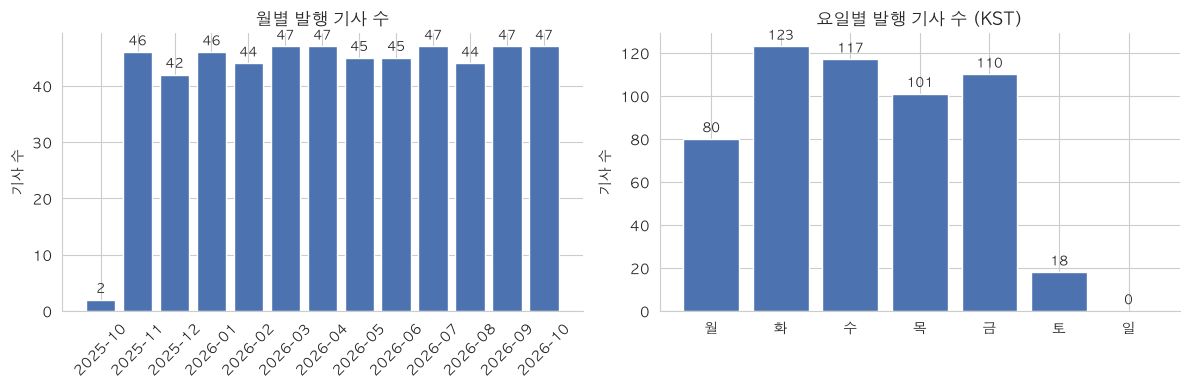

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

month_n = df["month"].value_counts().sort_index()
bars = axes[0].bar(month_n.index, month_n.values, color="#4C72B0")
axes[0].bar_label(bars, padding=2, fontsize=9)
axes[0].set_title("월별 발행 기사 수")
axes[0].tick_params(axis="x", rotation=45)

weekday_n = df["weekday"].value_counts().reindex(WEEKDAYS, fill_value=0)
bars = axes[1].bar(weekday_n.index, weekday_n.values, color="#4C72B0")
axes[1].bar_label(bars, padding=2, fontsize=9)
axes[1].set_title("요일별 발행 기사 수 (KST)")

for ax in axes:
    ax.set_ylabel("기사 수")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**읽는 법:** 처음과 마지막 달은 수집 기간이 며칠만 걸쳐 있어 기사 수가 적게 나오는 것이 정상입니다. 가운데 달들의 기사 수가 비슷하면 매체가 일정한 속도로 글을 올린다는 뜻이고, 그래야 월별 비율을 비교하는 의미가 있습니다.

### 4.2 저자

저자 수: 19명
상위 3명이 쓴 기사: 268건 (49%)


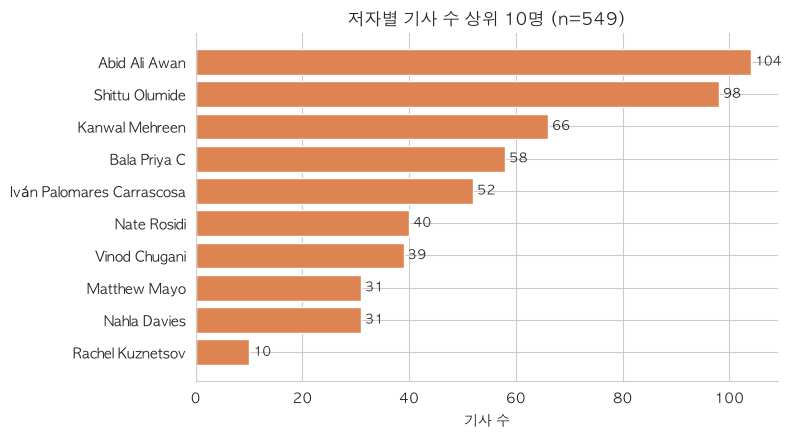

In [14]:
author_counts = df["author"].value_counts()
top3_n = author_counts.head(3).sum()
top3_share = top3_n / len(df)
print(f"저자 수: {len(author_counts)}명")
print(f"상위 3명이 쓴 기사: {top3_n}건 ({top3_share:.0%})")

plot_data = author_counts.head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(plot_data.index, plot_data.values, color="#DD8452")
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_title(f"저자별 기사 수 상위 10명 (n={len(df)})")
ax.set_xlabel("기사 수")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**읽는 법:** 소수 저자가 기사의 절반 이상을 쓴다면, 이후의 주제 분포는 업계 전체보다 "이 매체 편집진과 주요 저자가 중요하다고 본 것"에 가깝다고 해석해야 합니다. 8장에서 저자별로 주제가 얼마나 다른지 다시 확인합니다.

### 4.3 태그

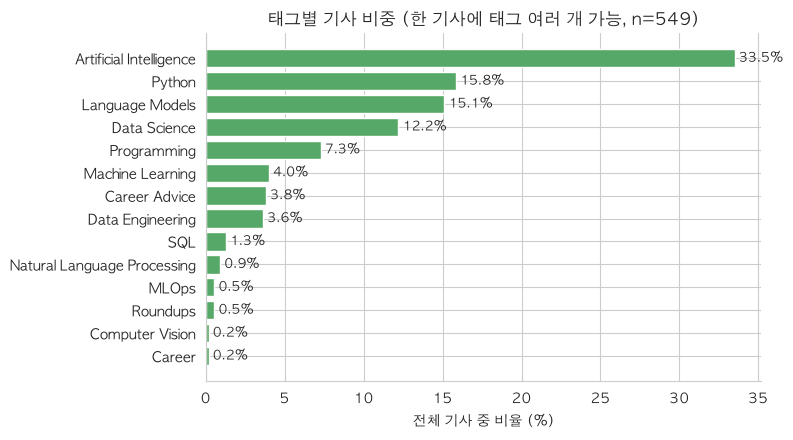

In [15]:
tag_counts = df["tag_list"].explode().dropna().value_counts()

if tag_counts.empty:
    print("태그가 없습니다 (RSS로 수집된 경우).")
else:
    plot_data = (tag_counts / len(df) * 100).sort_values()
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.barh(plot_data.index, plot_data.values, color="#55A868")
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
    ax.set_title(f"태그별 기사 비중 (한 기사에 태그 여러 개 가능, n={len(df)})")
    ax.set_xlabel("전체 기사 중 비율 (%)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

### 4.4 제목·요약문 길이

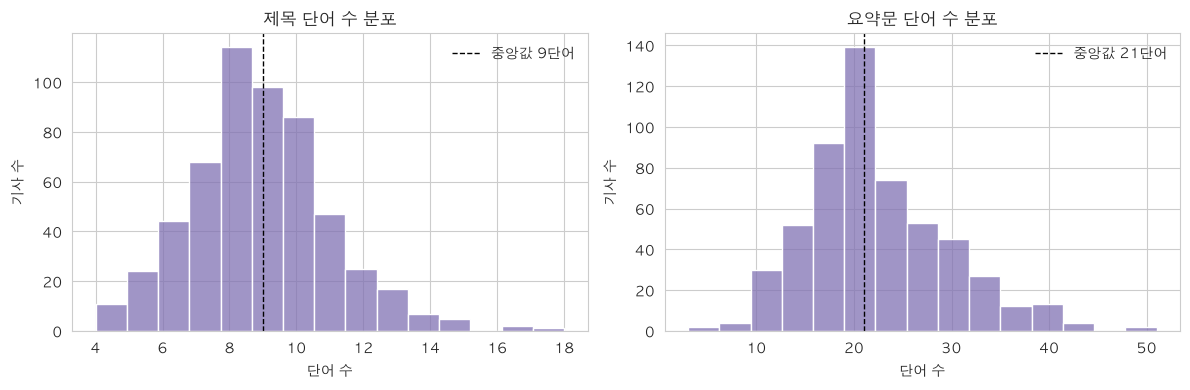

,title_words,summary_words
count,549.0,549.0
mean,8.8,22.2
std,2.2,7.2
min,4.0,3.0
25%,7.0,17.0
50%,9.0,21.0
75%,10.0,26.0
max,18.0,51.0


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, name in zip(axes, ["title_words", "summary_words"], ["제목", "요약문"]):
    sns.histplot(df[col], bins=15, color="#8172B3", ax=ax)
    ax.axvline(df[col].median(), color="black", linestyle="--", linewidth=1,
               label=f"중앙값 {df[col].median():.0f}단어")
    ax.set_title(f"{name} 단어 수 분포")
    ax.set_xlabel("단어 수")
    ax.set_ylabel("기사 수")
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

df[["title_words", "summary_words"]].describe().round(1)

**읽는 법:** 제목은 짧아서 핵심 단어가 잘 드러나고, 요약문은 길어서 "learn", "data" 같은 일반적인 단어가 많이 섞입니다. 그래서 6장의 단어 빈도 분석은 제목만 사용합니다.

# 5. 주제 분류 (규칙 기반, 하향식)

제목과 요약문을 합친 소문자 텍스트에 주제별 정규표현식을 적용해, 하나라도 일치하면 해당 주제로 분류합니다. 한 기사가 여러 주제에 동시에 해당할 수 있어서 주제별 비율의 합은 100%를 넘습니다.

**주제 체계:** "AI·데이터 기술 트렌드"를 보려면 생성형 AI만이 아니라 데이터·ML 쪽 주제도 잡혀야 합니다. 그래서 1년치 기사 제목을 직접 읽고 주제 23개를 만든 뒤 4개 영역으로 묶었습니다.

| 영역 | 주제 |
|---|---|
| 생성형 AI | 에이전트, AI 코딩, 로컬·소형 모델, MCP, RAG, 추론 효율·비용, 프롬프트, 파인튜닝, 평가·안전, 멀티모달, 모델·서비스 사용기, LLM 앱 개발 |
| 데이터 | 데이터 엔지니어링, SQL·DB, 데이터 처리 도구, 데이터 품질, 통계·분석·시각화 |
| ML·운영 | 고전 ML, NLP·문서 처리, MLOps·배포 |
| 개발 기본기·커리어 | 업무 자동화 도구, Python·개발 기본기, 커리어·학습 자료 |

**규칙을 다듬은 점:** 규칙마다 실제로 걸린 단어와 제목을 확인하며 고쳤습니다(5.3에서 직접 확인할 수 있습니다).
- `python`은 거의 모든 튜토리얼에 나오는 단어라 단독으로는 주제 판단에 쓰지 않고, "Python scripts/tricks"처럼 Python 자체를 다루는 표현만 개발 기본기로 셉니다.
- `check`는 "check out", "checkpoint"에, `deploy`·`production`은 "production-ready" 같은 수식어에 주로 걸려서 빼거나 좁혔습니다.
- `learn`은 "learn how to..."처럼 거의 모든 요약문에 나와서 커리어 규칙에 쓰지 않았습니다.
- `dashboard`, `analytics`, `visual`은 웹 개발·배포 글의 요약문에도 자주 나와서 "data analytics", "data visualization"처럼 데이터 분석을 가리키는 표현만 셉니다.
- `book`은 "notebook"에 걸리지 않게 단어 경계(`\b`)를 넣었습니다.
- "Claude Code", "Gemini CLI"는 코딩 도구이므로 모델·서비스 사용기에서는 제외했습니다.

### 5.1 주제 규칙 적용

In [17]:
# 영역 → 주제 → 정규식 (제목+요약문 소문자 텍스트에 적용)
THEME_RULES = {
    "생성형 AI": {
        "AI 에이전트": r"\bagents?\b|agentic|multi-agent|autonomous|openclaw|kimiclaw",
        "AI 코딩·바이브 코딩": (
            r"vibe cod|claude code|\bcodex\b|coding (?:agent|assistant|model|plan|cli"
            r"|platform|subscription)|agentic coding|agentic programming|ai coding"
            r"|ai code|gemini cli|opencode|antigravity|copilot|ai-generated code"
            r"|\.claude folder"
        ),
        "로컬·소형 모델": (
            r"\blocal(?:ly)?\b|small language|\bslms?\b|ollama|llama\.cpp|\bmlx\b"
            r"|on-device|smol|self-hosted (?:ai|llm)|tiny ai|raspberry pi|bitnet"
            r"|apple silicon|old laptop"
        ),
        "MCP·도구 호출": r"\bmcps?\b|model context protocol|tool calling|function calling",
        "RAG·검색·임베딩": (
            r"\brag\b|retrieval|vector (?:search|database|db|store)|embedding"
            r"|semantic search"
        ),
        "추론 효율·비용": (
            r"inference|latency|quantiz|turboquant|kv cache|key-value cache"
            r"|speculative|\bprun|token (?:usage|compression)|saving token"
            r"|wasting tokens|cheap|on a budget|cost-effective|inference cost|batching"
        ),
        "프롬프트·컨텍스트 엔지니어링": (
            r"prompt|context engineering|specification engineering|concept engineering"
            r"|structured (?:output|generation)|constrain\w* (?:decoding|output)"
            r"|outlines"
        ),
        "파인튜닝·모델 학습": (
            r"fine-?tun|pretrain|\blora\b|unsloth|llm training|merging language"
            r"|training on limited"
        ),
        "평가·신뢰성·안전": (
            r"\bevals?\b|evaluation|benchmark|hallucinat|guardrail|explainab"
            r"|calibration|\bbias|security|ai detector|trusting"
        ),
        "멀티모달(음성·이미지·영상)": (
            r"voice|speech|transcri|whisper|\btts\b|video|\bimages?\b|\bvision\b"
            r"|\bocr\b|multimodal|\bomni\b|music"
        ),
        "모델·서비스 사용기": (
            r"chatgpt|\bgpt-|openai(?! codex)|claude(?! code)|gemini(?! cli)|gemma"
            r"|qwen|deepseek|\bgrok|\bkimi\b|minimax|mistral|notebooklm|perplexity"
            r"|hugging face models"
        ),
        "LLM 앱 개발·API": (
            r"langchain|llamaindex|llm (?:apps?|applications?|engineer\w*|updates)"
            r"|openrouter|api providers?|llm api|claude api|agents? sdk"
            r"|agent development kit|ai orchestration|transformers\.js"
            r"|hugging face (?:spaces|primer)|gradio|comfyui|ai studio|vertex ai"
            r"|scikit-llm"
        ),
    },
    "데이터": {
        "데이터 엔지니어링·파이프라인": (
            r"data engineer|data pipeline|\betl\b|\belt\b|airflow|\bdbt\b|spark|kafka"
            r"|warehouse|lakehouse|data lake|data mesh|snowflake|databricks|parquet"
            r"|\barrow\b|duckdb|feature store|\bdask\b|kedro|large-scale data"
            r"|billion-row|large datasets?|large json|data processing"
        ),
        "SQL·데이터베이스": (
            r"\bsql\b|postgres|mysql|sqlite|database|window function|\bjoins?\b"
        ),
        "데이터 처리 도구(pandas·polars)": (
            r"pandas|polars|numpy|dataframe|\bvaex\b|pyjanitor|\bcsv\b|excel|marimo"
            r"|\beda\b|exploratory data"
        ),
        "데이터 품질·정제·프라이버시": (
            r"data quality|validation|data cleaning|clean(?:ing)? messy|messy (?:data"
            r"|csv)|missing data|imputation|outlier|observability|synthetic data"
            r"|anonymi|privacy|mimesis"
        ),
        "통계·분석·시각화": (
            r"statistic|probabilit|distribution|a/b test|hypothesis|central limit"
            r"|time series|forecast|scipy|statsmodels|pingouin|data visuali"
            r"|auto-visuali|visualizing patterns|storytelling|data analytics"
            r"|analytics (?:problems|patterns|stack)|in analytics"
        ),
    },
    "ML·운영": {
        "고전 ML·특성 공학": (
            r"scikit-learn|sklearn|xgboost|feature (?:engineering|selection)"
            r"|hyperparameter|overfitting|classifier|smote|automl"
            r"|machine learning algorithm|graph neural|loss function|\btpot\b|sktime"
            r"|predictive model"
        ),
        "NLP·문서 처리": (
            r"\bnlp\b|spacy|nltk|entity recognition|text classification"
            r"|text processing|text preprocessing|document parsing|docling"
            r"|data extraction|langextract|textstat|\bocr\b"
        ),
        "MLOps·배포·인프라": (
            r"mlops|llmops|deploy\w* (?:ai|ml|models?|language models?|llms?|agents?"
            r"|your first|it headlessly)|model deployment|language model deployment"
            r"|docker|kubernetes|fastapi|model serving|ci/cd|self-host"
            r"|production (?:llms?|ai|ml)\b"
        ),
    },
    "개발 기본기·커리어": {
        "업무 자동화 도구": (
            r"\bn8n\b|zapier|make\.com|google opal|automation tools|ai automations?\b"
            r"|workflow automation"
        ),
        "Python·개발 기본기": (
            r"python (?:scripts?|concepts|tricks|functions|decorators|data classes"
            r"|dictionary|best practices|mistakes|one-liners|techniques|project setup"
            r"|foundations|design patterns|frameworks|async)|python code|\buv\b|ruff"
            r"|pixi|\bgit\b|logging|clean python|readable python|registry pattern"
            r"|install python|python libraries|python environments"
            r"|python applications?|python projects"
        ),
        "커리어·학습 자료": (
            r"roadmap|career|courses?\b|interview|resume|hiring|job (?:markets?"
            r"|postings?|descriptions?)|for your job|analyst jobs|\bbooks?\b"
            r"|newsletters?|youtube channels|influencers|zoomcamp|starter kit"
            r"|free resources|resources to learn|github repositories to (?:master"
            r"|learn|ace)|engineer in 20\d\d|forward deployed|ai experience"
        ),
    },
}

THEMES = {theme: pattern for rules in THEME_RULES.values() for theme, pattern in rules.items()}
THEME_DOMAIN = {theme: domain for domain, rules in THEME_RULES.items() for theme in rules}
DOMAINS = list(THEME_RULES)
DOMAIN_COL = {domain: f"영역:{domain}" for domain in DOMAINS}   # 영역 해당 여부를 담을 컬럼 이름
DOMAIN_COLORS = {"생성형 AI": "#4C72B0", "데이터": "#55A868", "ML·운영": "#DD8452", "개발 기본기·커리어": "#8C8C8C"}

for theme, pattern in THEMES.items():
    df[theme] = df["text"].str.contains(pattern, regex=True)
for domain, rules in THEME_RULES.items():
    df[DOMAIN_COL[domain]] = df[list(rules)].any(axis=1)   # 영역 안의 주제가 하나라도 걸리면 해당


def show_titles(theme, n=8):
    """특정 주제로 분류된 기사 제목 미리보기"""
    return df.loc[df[theme], ["published", "title"]].head(n).reset_index(drop=True)


def matched_terms(theme, n=6):
    """주제 규칙에서 실제로 걸린 표현 상위 n개 (어떤 단어 때문에 주제가 커졌는지 확인용)"""
    hits = Counter(m for t in df.loc[df[theme], "text"] for m in set(re.findall(THEMES[theme], t)))
    return ", ".join(f"{w}({c})" for w, c in hits.most_common(n))


n_themes = df[list(THEMES)].sum(axis=1)
print(f"주제 {len(THEMES)}개, 영역 {len(DOMAINS)}개")
print(f"주제가 하나도 안 걸린 기사: {(n_themes == 0).sum()}건 ({(n_themes == 0).mean():.0%})")
print(f"기사당 평균 주제 수: {n_themes.mean():.1f}개")

주제 23개, 영역 4개
주제가 하나도 안 걸린 기사: 54건 (10%)
기사당 평균 주제 수: 1.6개


### 5.2 영역·주제별 기사 수와 비중

In [18]:
domain_summary = pd.DataFrame({
    "기사 수": [df[DOMAIN_COL[d]].sum() for d in DOMAINS],
    "비중(%)": [round(df[DOMAIN_COL[d]].mean() * 100, 1) for d in DOMAINS],
}, index=DOMAINS)
display(domain_summary)

theme_summary = (
    df[list(THEMES)].sum()
    .sort_values(ascending=False)
    .rename("기사 수")
    .to_frame()
)
theme_summary["비중(%)"] = (theme_summary["기사 수"] / len(df) * 100).round(1)
theme_summary.insert(0, "영역", theme_summary.index.map(THEME_DOMAIN))
theme_summary.insert(0, "순위", range(1, len(theme_summary) + 1))
THEME_ORDER = list(theme_summary.index)   # 이후 표·그래프는 전체 순위 순서로 정렬
theme_summary

,기사 수,비중(%)
생성형 AI,294,53.6
데이터,123,22.4
ML·운영,76,13.8
개발 기본기·커리어,143,26.0


,순위,영역,기사 수,비중(%)
AI 에이전트,1,생성형 AI,113,20.6
Python·개발 기본기,2,개발 기본기·커리어,71,12.9
커리어·학습 자료,3,개발 기본기·커리어,63,11.5
모델·서비스 사용기,4,생성형 AI,59,10.7
AI 코딩·바이브 코딩,5,생성형 AI,57,10.4
로컬·소형 모델,6,생성형 AI,56,10.2
MLOps·배포·인프라,7,ML·운영,43,7.8
데이터 품질·정제·프라이버시,8,데이터,36,6.6
LLM 앱 개발·API,9,생성형 AI,34,6.2
데이터 처리 도구(pandas·polars),10,데이터,34,6.2


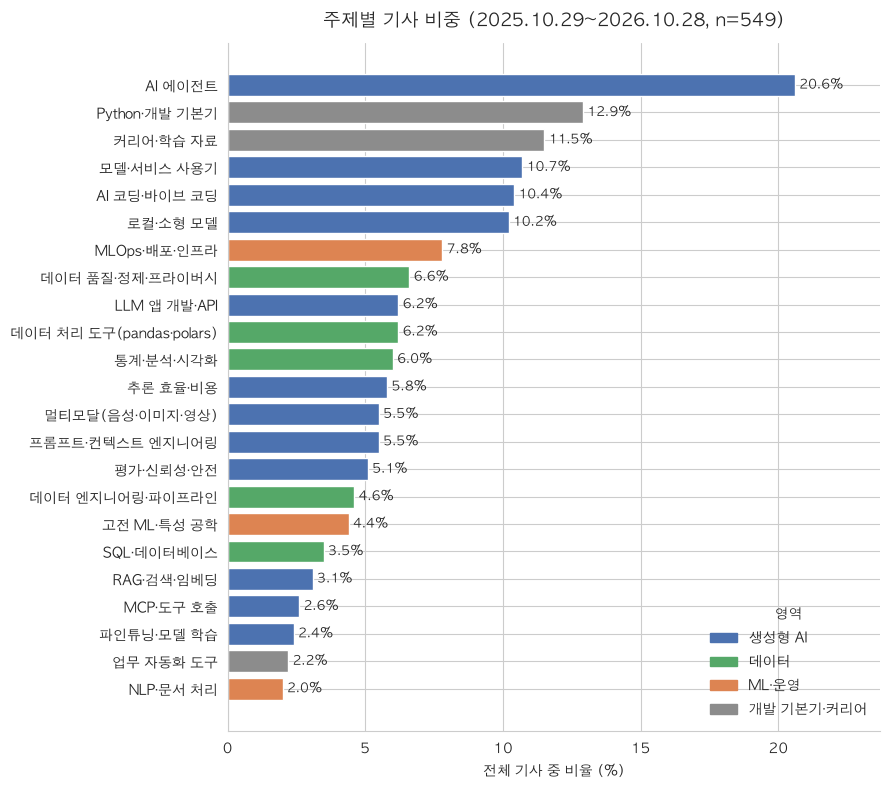

In [19]:
plot_data = theme_summary.sort_values("비중(%)")

fig, ax = plt.subplots(figsize=(9, 8))
bars = ax.barh(plot_data.index, plot_data["비중(%)"], color=plot_data["영역"].map(DOMAIN_COLORS))
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
ax.set_title(f"주제별 기사 비중 ({PERIOD}, n={len(df)})", fontsize=13, pad=12)
ax.set_xlabel("전체 기사 중 비율 (%)")
ax.set_xlim(0, plot_data["비중(%)"].max() * 1.15)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in DOMAIN_COLORS.values()]
ax.legend(handles, DOMAIN_COLORS.keys(), title="영역", loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**읽는 법:** 영역 비중은 "그 영역의 주제가 하나라도 걸린 기사"의 비율입니다. 막대 색이 영역을 나타내므로, 상위권이 어느 영역에 몰려 있는지 함께 보세요.

### 5.3 규칙 검증: 무엇 때문에 걸렸고, 어떤 기사가 걸렸나

규칙이 의도대로 기사를 골랐는지 두 가지로 확인합니다.
1. 상위 주제마다 **실제로 걸린 표현**을 셉니다. 한 단어가 대부분을 차지하거나 엉뚱한 단어가 많으면 규칙을 다듬어야 합니다.
2. 상위 3개 주제의 **실제 기사 제목**을 봅니다.

In [20]:
display(pd.Series({t: matched_terms(t) for t in THEME_ORDER[:8]}, name="많이 걸린 표현(기사 수)").to_frame())

pd.concat({theme: show_titles(theme, n=6) for theme in THEME_ORDER[:3]})

,많이 걸린 표현(기사 수)
AI 에이전트,"agents(50), agentic(43), agent(42), autonomous(12), openclaw(10), multi-agent(5)"
Python·개발 기본기,"python scripts(14), python libraries(10), python code(5), python tricks(4), python concepts(4), ..."
커리어·학습 자료,"roadmap(10), interview(10), github repositories to master(8), books(7), courses(6), course(6)"
모델·서비스 사용기,"openai(13), claude(13), gemini(9), notebooklm(8), chatgpt(8), qwen(5)"
AI 코딩·바이브 코딩,"ai coding(15), vibe cod(14), claude code(13), opencode(5), ai code(5), coding agent(4)"
로컬·소형 모델,"local(33), locally(19), ollama(10), small language(7), slm(4), llama.cpp(3)"
MLOps·배포·인프라,"docker(16), self-host(10), mlops(5), fastapi(5), deploying ai(2), deploy your first(2)"
데이터 품질·정제·프라이버시,"validation(9), privacy(6), data quality(6), data cleaning(5), outlier(3), mimesis(3)"


published  \
AI 에이전트       0 2026-10-26 23:00:00   
              1 2026-10-23 21:00:00   
              2 2026-10-22 21:00:00   
              3 2026-10-21 21:00:00   
              4 2026-10-20 01:00:00   
              5 2026-10-16 23:00:00   
Python·개발 기본기 0 2026-10-26 21:00:00   
              1 2026-10-02 23:00:17   
              2 2026-10-01 21:00:14   
              3 2026-09-25 21:00:22   
              4 2026-09-21 23:00:07   
              5 2026-09-14 23:00:09   
커리어·학습 자료     0 2026-10-26 23:00:00   
              1 2026-10-23 23:00:00   
              2 2026-10-20 23:00:00   
              3 2026-10-16 21:00:00   
              4 2026-10-13 23:00:00   
              5 2026-10-08 21:00:00   

                                                                                         title  
AI 에이전트       0              Building Your First AI Agent in Python with the OpenAI Agents SDK  
              1                                 5 Free AI Coding Agents You Should Try in 2026  
              2      Google Open-Sources Harness²: Self-Improving AI Agents Without Retraining  
              3                                 5 Best GitHub Repositories for AI Agent Skills  
              4    Claude Haiku 5.5: What’s New and How to Use It for Fast, Cheap AI Workflows  
              5  Agentic RAG vs. Naive RAG: When Your Retrieval System Should Think for Itself  
Python·개발 기본기 0                          7 Advanced Python Design Patterns for Data Scientists  
              1                    Python Foundations for Engineering: A KDnuggets Cheat Sheet  
              2               10 Python One-Liners That Will Make Your Code Cleaner and Faster  
              3                        7 Advanced Python Tricks to Level Up Your Coding Skills  
              4                                   How to Turn a Python Script Into an AI Agent  
              5   7 Python Best Practices Senior Developers Follow (That Beginners Often Miss)  
커리어·학습 자료     0                     The Roadmap to Becoming a Computer Vision Engineer in 2026  
              1           What Companies Actually Mean When They Say They Want “AI Experience”  
              2                          The Roadmap to Becoming an AI Product Manager in 2026  
              3                           5 Best Resources to Learn About World Models in 2026  
              4                            The Roadmap to Mastering Agentic AI Systems in 2026  
              5                        7 Best Resources to Learn About Self-Evolving AI Agents

**읽는 법:** 한 표현이 주제 대부분을 차지하더라도 그 표현이 주제를 정확히 가리키면(예: 에이전트의 agents·agentic) 문제가 없습니다. 반대로 여러 뜻으로 쓰이는 단어(예: local, prompt)가 많다면 6장의 단어 빈도와 비교해서 판단합니다.

# 6. 키워드 분석 (빈도 기반, 상향식)

5장은 미리 정한 규칙으로 기사를 찾는 방법이라, 규칙에 없는 단어는 놓칩니다. 이 장에서는 반대로 규칙 없이 **제목에 실제로 많이 쓰인 단어**를 셉니다.

- 제목만 사용합니다. (요약문은 일반적인 단어가 많아서 제외)
- 한 기사 안에서 같은 단어는 한 번만 셉니다. 즉 값은 "그 단어가 제목에 들어간 기사 수"입니다.
- agents·agentic은 agent로, models는 model로처럼 같은 뜻의 단어를 묶습니다.

### 6.1 제목 키워드 상위 20개

In [21]:
# 의미 없는 단어(불용어)와 사이트 이름은 제외
STOPWORDS = set("""
a an the and or of to in on for with by from at as is are be your you how what why when which
that this these those it its into vs using use used can do does i we my our not more than best
top free new guide about without should will just get it's here's what's one two three four five
six seven eight nine ten actually really kdnuggets
""".split())

# 단수·복수, 동사 활용을 하나로 묶기
NORMALIZE = {"agents": "agent", "agentic": "agent", "models": "model", "llms": "llm",
             "building": "build", "builds": "build", "tools": "tool", "workflows": "workflow"}


def title_words(title):
    """제목을 소문자 단어 목록으로 분리 (open-source, c++ 같은 표현은 유지)"""
    title = title.lower().replace("’", "'")
    return re.findall(r"[a-z][a-z0-9.+#'-]*[a-z0-9+#]|[a-z]", title)


def keywords(title):
    """불용어를 빼고 정규화한 키워드 집합 (한 기사에서 같은 단어는 1번만 셈)"""
    return {NORMALIZE.get(w, w) for w in title_words(title) if w not in STOPWORDS and len(w) > 1}


def bigrams(title):
    """연속된 두 단어 묶음 (둘 중 하나라도 불용어면 제외)"""
    w = title_words(title)
    return {f"{a} {b}" for a, b in zip(w, w[1:]) if a not in STOPWORDS and b not in STOPWORDS}


df["keywords"] = df["title"].map(keywords)
word_counts = Counter(w for kws in df["keywords"] for w in kws)

top_words = pd.DataFrame(word_counts.most_common(20), columns=["키워드", "기사 수"])
top_words["비중(%)"] = (top_words["기사 수"] / len(df) * 100).round(1)
top_words.index = range(1, len(top_words) + 1)
top_words

,키워드,기사 수,비중(%)
1,ai,142,25.9
2,data,94,17.1
3,python,93,16.9
4,agent,76,13.8
5,build,57,10.4
6,model,54,9.8
7,llm,33,6.0
8,coding,29,5.3
9,tool,25,4.6
10,code,24,4.4


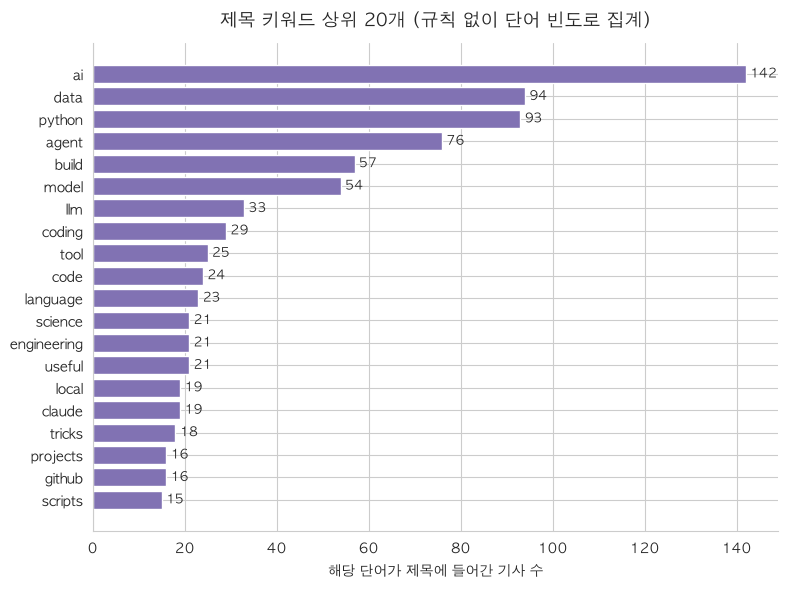

In [22]:
plot_data = top_words.set_index("키워드")["기사 수"].sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(plot_data.index, plot_data.values, color="#8172B3")
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_title("제목 키워드 상위 20개 (규칙 없이 단어 빈도로 집계)", fontsize=13, pad=12)
ax.set_xlabel("해당 단어가 제목에 들어간 기사 수")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 6.2 자주 함께 쓰인 두 단어 표현

한 단어만 보면 뜻이 모호한 경우가 있습니다(예: "small"). 두 단어 표현("small language")으로 보면 맥락이 분명해집니다.

In [23]:
bigram_counts = Counter(b for t in df["title"] for b in bigrams(t))
top_bigrams = pd.DataFrame(bigram_counts.most_common(15), columns=["두 단어 표현", "기사 수"])
top_bigrams.index = range(1, len(top_bigrams) + 1)
top_bigrams

,두 단어 표현,기사 수
1,data science,21
2,ai agents,18
3,agentic ai,18
4,language models,17
5,github repositories,14
6,useful python,14
7,python scripts,14
8,ai coding,11
9,machine learning,11
10,data scientists,10


### 6.3 기업·모델 언급

제목과 요약문에서 주요 AI 기업과 모델 이름이 언급된 기사 수를 셉니다.

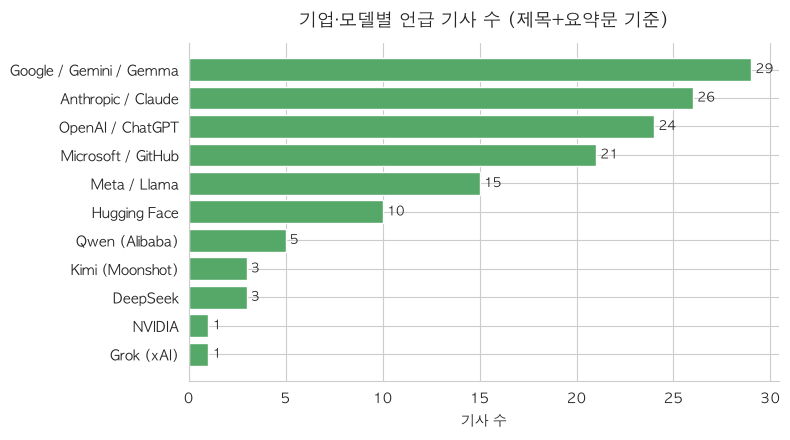

In [24]:
VENDORS = {
    "OpenAI / ChatGPT": r"openai|chatgpt|\bgpt",
    "Google / Gemini / Gemma": r"google|gemini|gemma|kaggle",
    "Anthropic / Claude": r"claude|anthropic",
    "Meta / Llama": r"\bmeta\b|llama",
    "Microsoft / GitHub": r"microsoft|github",
    "Hugging Face": r"hugging face",
    "Qwen (Alibaba)": r"qwen",
    "DeepSeek": r"deepseek",
    "Kimi (Moonshot)": r"kimi",
    "NVIDIA": r"nvidia",
    "Grok (xAI)": r"grok",
}
vendor_counts = pd.Series(
    {name: df["text"].str.contains(p, regex=True).sum() for name, p in VENDORS.items()},
    name="언급 기사 수",
).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(vendor_counts.index, vendor_counts.values, color="#55A868")
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_title("기업·모델별 언급 기사 수 (제목+요약문 기준)", fontsize=13, pad=12)
ax.set_xlabel("기사 수")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**읽는 법:** "ai"처럼 거의 모든 글에 붙는 단어는 빼고 봅니다. 5장의 상위 주제와 관련된 단어(예: agent, local, coding)가 6장에서도 상위에 있으면 두 방법이 같은 결론을 가리키는 것이므로 결과를 더 믿을 수 있습니다.

반대로 빈도가 높아도 트렌드가 아닌 표현이 있습니다. "cheat sheet"처럼 매체의 연재 시리즈 이름이거나, 특정 제품명이 반복되는 경우입니다. 이런 표현은 매체의 편집 사정을 반영하므로 트렌드 해석에서 빼고 봅니다.

# 7. 시간에 따른 변화

큰 그림(영역)에서 시작해 세부(주제, 키워드)로 내려갑니다.

### 7.1 영역별 분기 비중

분기별 기사 수: {'Q1(25.10.29~01.28)': 131, 'Q2(26.01.28~04.29)': 142, 'Q3(26.04.29~07.29)': 133, 'Q4(26.07.29~10.28)': 143}


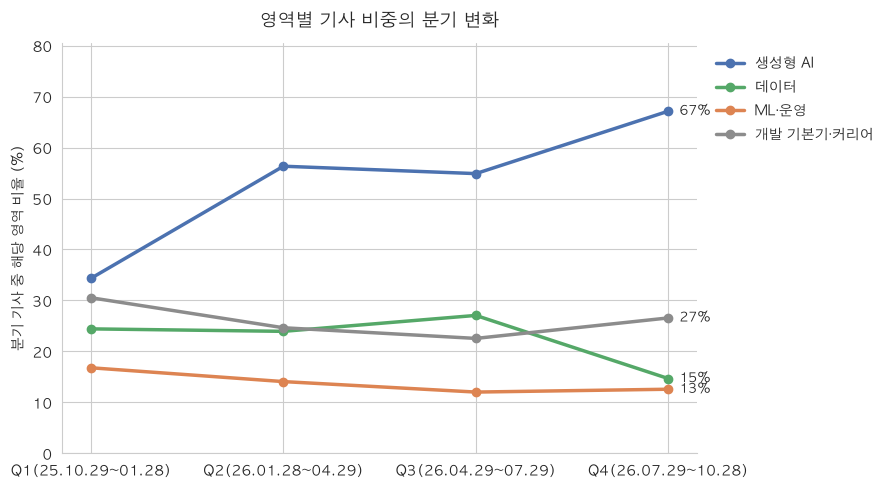

quarter,Q1(25.10.29~01.28),Q2(26.01.28~04.29),Q3(26.04.29~07.29),Q4(26.07.29~10.28)
생성형 AI,34.4,56.3,54.9,67.1
데이터,24.4,23.9,27.1,14.7
ML·운영,16.8,14.1,12.0,12.6
개발 기본기·커리어,30.5,24.6,22.6,26.6


,전반(10/29~05/01),후반(05/01~10/28),변화(%p),p값
생성형 AI,127,167,14.8,0.001
데이터,66,57,-3.2,0.369
ML·운영,42,34,-2.9,0.331
개발 기본기·커리어,76,67,-3.2,0.395


In [25]:
def two_prop_p(a, n1, b, n2):
    """두 비율(a/n1, b/n2) 차이의 양측 p값 (정규근사)"""
    p = (a + b) / (n1 + n2)
    se = sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    if se == 0:
        return 1.0
    z = (b / n2 - a / n1) / se
    return 1 - erf(abs(z) / sqrt(2))


quarter_n = df["quarter"].value_counts().reindex(QUARTERS)
print("분기별 기사 수:", quarter_n.to_dict())

domain_q = df.groupby("quarter")[list(DOMAIN_COL.values())].mean().mul(100).reindex(QUARTERS)
domain_q.columns = DOMAINS

fig, ax = plt.subplots(figsize=(9, 5))
for domain in DOMAINS:
    ax.plot(range(len(QUARTERS)), domain_q[domain], marker="o", linewidth=2.5,
            color=DOMAIN_COLORS[domain], label=domain)
    ax.annotate(f"{domain_q[domain].iloc[-1]:.0f}%", (len(QUARTERS) - 1, domain_q[domain].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_xticks(range(len(QUARTERS)), QUARTERS)
ax.set_title("영역별 기사 비중의 분기 변화", fontsize=13, pad=12)
ax.set_ylabel("분기 기사 중 해당 영역 비율 (%)")
ax.set_ylim(0, domain_q.values.max() * 1.2)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# 영역 단위로 전반 vs 후반 비교 (7.3과 같은 방식)
half_n = df["half"].value_counts().reindex(HALVES)
domain_half = pd.DataFrame({h: [df.loc[df["half"] == h, DOMAIN_COL[d]].sum() for d in DOMAINS] for h in HALVES},
                           index=DOMAINS)
domain_half["변화(%p)"] = ((domain_half[HALVES[1]] / half_n.iloc[1] - domain_half[HALVES[0]] / half_n.iloc[0]) * 100).round(1)
domain_half["p값"] = [round(two_prop_p(a, half_n.iloc[0], b, half_n.iloc[1]), 3)
                     for a, b in zip(domain_half[HALVES[0]], domain_half[HALVES[1]])]

display(domain_q.round(1).T)
domain_half

**읽는 법:** 한 기사가 여러 영역에 걸칠 수 있어서 네 선의 합은 100%가 아닙니다. 선 하나만 보지 말고, 영역끼리 상대적으로 어떻게 움직이는지를 봅니다. 한 분기만 튀고 다시 돌아오면 연재·기획 같은 일시적인 영향일 가능성이 큽니다. 아래 표는 전반 6개월과 후반 6개월의 영역별 기사 수이고, p값이 0.05보다 작으면 우연으로 보기 어려운 변화입니다(p값은 7.3에서 자세히 설명합니다).

### 7.2 주제별 분기 비중

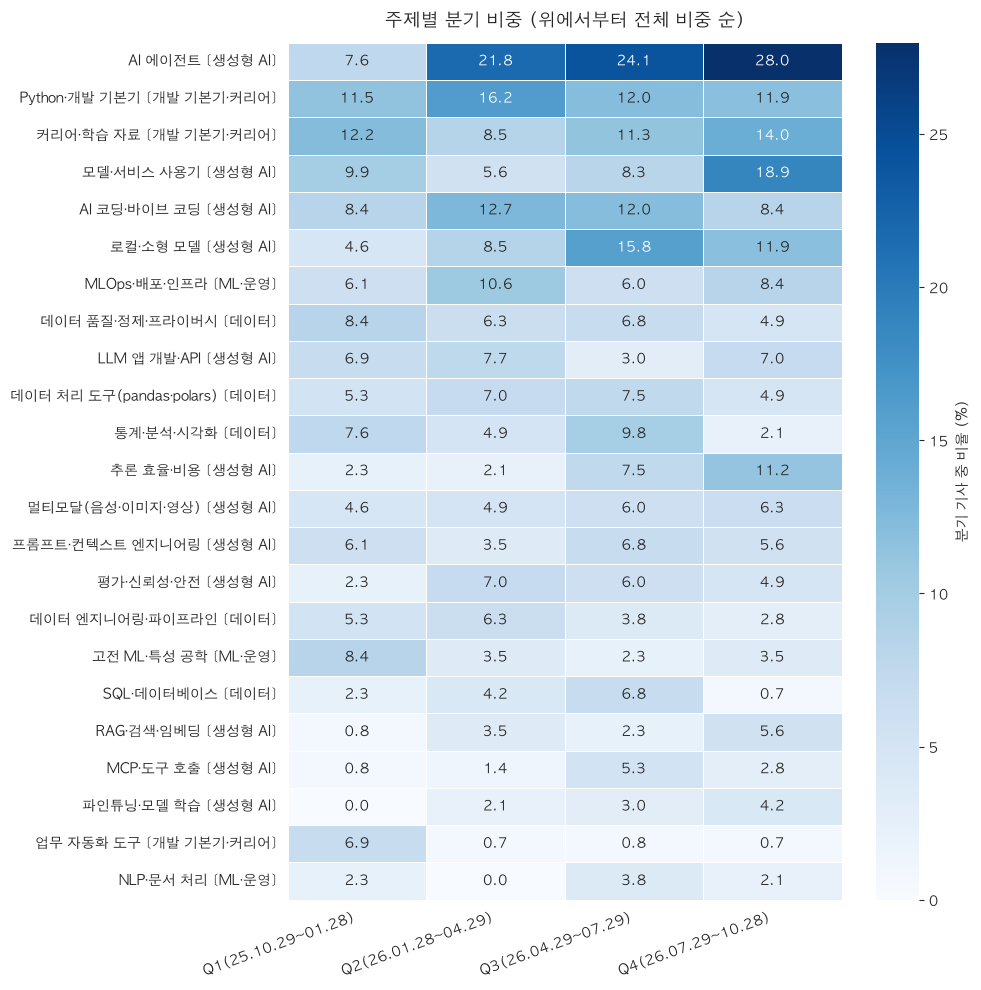

In [26]:
quarter_share = df.groupby("quarter")[THEME_ORDER].mean().mul(100).reindex(QUARTERS).T
quarter_share.index = [f"{t} [{THEME_DOMAIN[t]}]" for t in quarter_share.index]

fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(quarter_share, annot=True, fmt=".1f", cmap="Blues", linewidths=0.5,
            cbar_kws={"label": "분기 기사 중 비율 (%)"}, ax=ax)
ax.set_title("주제별 분기 비중 (위에서부터 전체 비중 순)", fontsize=13, pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**읽는 법:** 행을 왼쪽에서 오른쪽으로 읽습니다. 색이 점점 진해지면 떠오르는 주제, 옅어지면 식는 주제입니다. 한 분기에 130~140건이라 기사 1건이 약 0.7%p이므로, 1~2%p 차이는 우연일 수 있습니다.

### 7.3 전반 vs 후반: 어떤 주제가 늘고 줄었나

전반 6개월과 후반 6개월의 주제 비중을 비교합니다. 변화가 우연인지 가늠하기 위해 **두 비율 차이 검정의 p값**을 함께 계산하고, p값이 0.05보다 작은 경우만 "증가" 또는 "감소"로 판정합니다.
단, 주제 23개를 한꺼번에 검정하므로 우연히 한 개 정도는 0.05 아래로 나올 수 있습니다. 그래서 p값만 보지 않고 7.2의 분기 흐름이 같은 방향인지도 함께 확인합니다.

구간별 기사 수: {'전반(10/29~05/01)': 275, '후반(05/01~10/28)': 274}


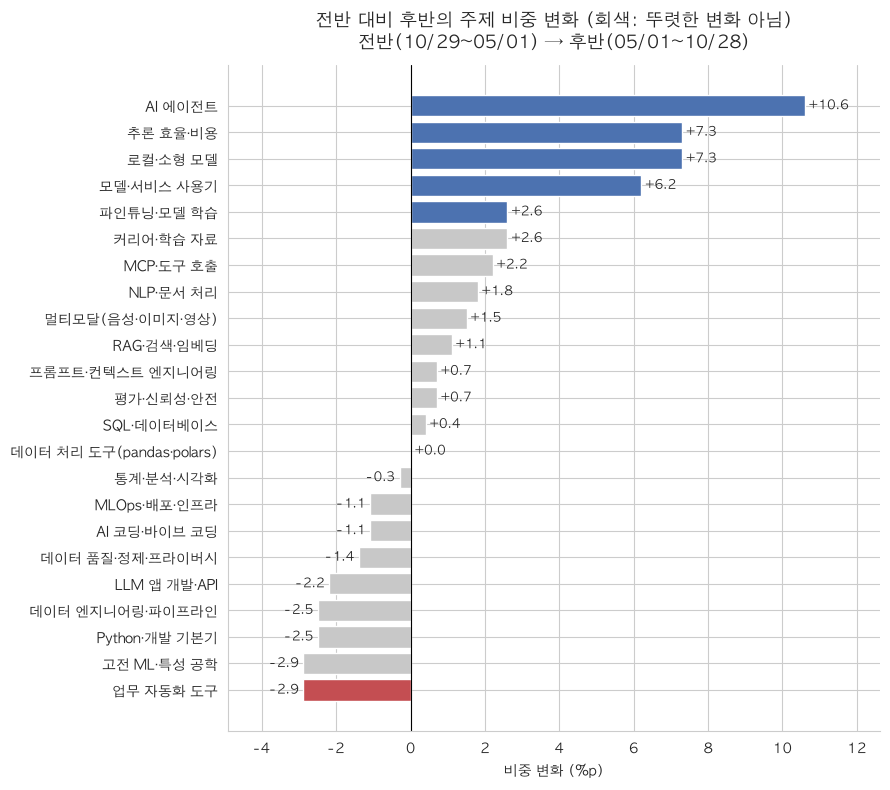

half,전반(10/29~05/01),후반(05/01~10/28),변화(%p),p값,판정
업무 자동화 도구,10,2,-2.9,0.020,감소
고전 ML·특성 공학,16,8,-2.9,0.097,-
Python·개발 기본기,39,32,-2.5,0.382,-
데이터 엔지니어링·파이프라인,16,9,-2.5,0.155,-
LLM 앱 개발·API,20,14,-2.2,0.293,-
데이터 품질·정제·프라이버시,20,16,-1.4,0.498,-
AI 코딩·바이브 코딩,30,27,-1.1,0.685,-
MLOps·배포·인프라,23,20,-1.1,0.643,-
통계·분석·시각화,17,16,-0.3,0.866,-
데이터 처리 도구(pandas·polars),17,17,0.0,0.991,-


In [27]:
half_n = df["half"].value_counts().reindex(HALVES)
half_theme = df.groupby("half")[THEME_ORDER].sum().T[HALVES]
half_share = half_theme.div(half_n, axis=1).mul(100)
half_theme["변화(%p)"] = (half_share[HALVES[1]] - half_share[HALVES[0]]).round(1)
half_theme["p값"] = [two_prop_p(a, half_n.iloc[0], b, half_n.iloc[1])
                    for a, b in zip(half_theme[HALVES[0]], half_theme[HALVES[1]])]
significant = half_theme["p값"] < 0.05
half_theme["판정"] = np.select(
    [significant & (half_theme["변화(%p)"] > 0), significant & (half_theme["변화(%p)"] < 0)],
    ["증가", "감소"], default="-")
half_theme["p값"] = half_theme["p값"].round(3)
half_theme = half_theme.sort_values("변화(%p)")

print("구간별 기사 수:", half_n.to_dict())

fig, ax = plt.subplots(figsize=(9, 8))
colors = half_theme["판정"].map({"증가": "#4C72B0", "감소": "#C44E52", "-": "#C8C8C8"})
bars = ax.barh(half_theme.index, half_theme["변화(%p)"], color=colors)
ax.bar_label(bars, fmt="%+.1f", padding=3, fontsize=9)
ax.axvline(0, color="black", linewidth=0.8)
ax.margins(x=0.15)   # 막대 끝 숫자가 잘리지 않도록 여백
ax.set_title(f"전반 대비 후반의 주제 비중 변화 (회색: 뚜렷한 변화 아님)\n{HALVES[0]} → {HALVES[1]}", fontsize=13, pad=12)
ax.set_xlabel("비중 변화 (%p)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

half_theme

**읽는 법:** 색이 있는 막대만 "늘었다/줄었다"고 말할 수 있는 주제입니다. 회색 막대는 막대가 길어 보여도 표본 크기로는 우연과 구분되지 않습니다. 건수가 적은 주제(예: 3건 → 10건)는 비율로는 크게 늘어 보여도, 실제로는 몇 건 차이라는 점을 표에서 확인하세요.

### 7.4 떠오른 주제와 식은 주제의 월별 추이

7.3에서 "증가"와 "감소"로 판정된 주제를 월별로 그립니다. 한 달 기사가 45건 정도라 월별 값은 출렁임이 커서, 점은 월별 실제 값으로, 선은 3개월 이동평균으로 표시합니다.

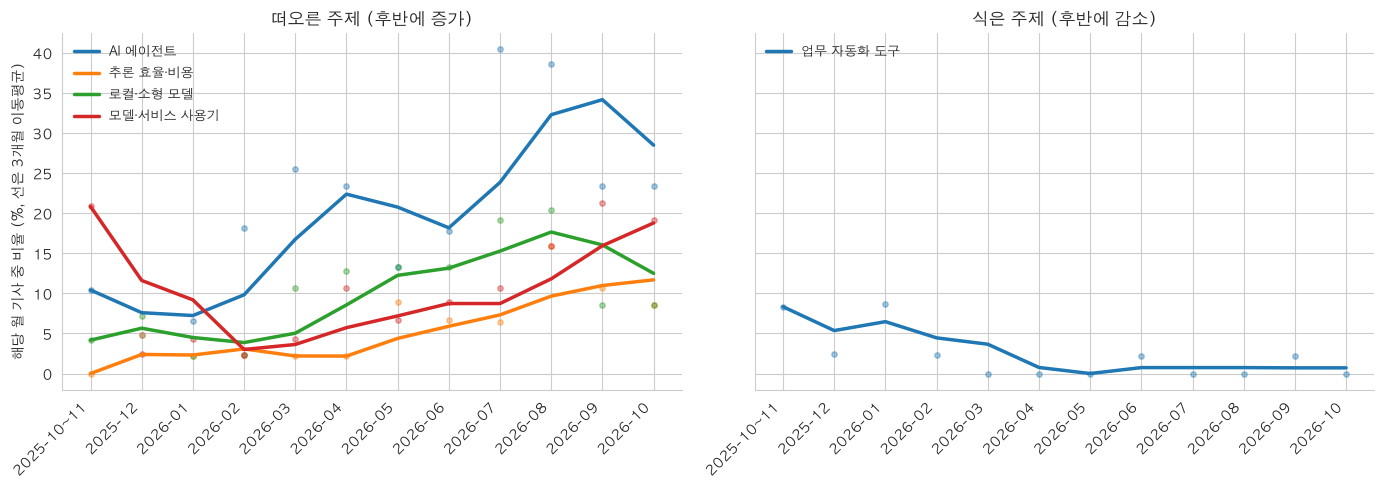

In [28]:
RISING = half_theme[half_theme["판정"] == "증가"].sort_values("변화(%p)", ascending=False).index[:4].tolist()
FALLING = half_theme[half_theme["판정"] == "감소"].index[:4].tolist()   # 가장 많이 줄어든 순

monthly_share = df.groupby("month_group")[THEME_ORDER].mean().mul(100)
smooth = monthly_share.rolling(3, min_periods=1).mean()   # 3개월 이동평균
x = range(len(monthly_share))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, group, title in zip(axes, [RISING, FALLING], ["떠오른 주제 (후반에 증가)", "식은 주제 (후반에 감소)"]):
    if not group:
        ax.text(0.5, 0.5, "해당 주제 없음", ha="center", va="center", transform=ax.transAxes)
    for theme in group:
        line, = ax.plot(x, smooth[theme], linewidth=2.5, label=theme)
        ax.scatter(x, monthly_share[theme], s=15, alpha=0.4, color=line.get_color())
    ax.set_xticks(list(x), monthly_share.index, rotation=45, ha="right")
    ax.set_title(title, fontsize=12)
    ax.legend(loc="upper left", frameon=False, fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("해당 월 기사 중 비율 (%, 선은 3개월 이동평균)")
plt.tight_layout()
plt.show()

**읽는 법:** 선이 1년 내내 한 방향으로 움직이면 추세이고, 한두 달만 튀었다가 돌아오면 일시적인 화제나 연재의 영향일 가능성이 큽니다.

### 7.5 전반 vs 후반: 키워드

전체 기간에 10건 이상 나온 단어만 대상으로, 비중이 가장 많이 줄어든 단어와 늘어난 단어를 봅니다. 주제 규칙과 상관없이 센 결과이므로 7.3의 결과를 교차 확인하는 용도입니다.

In [29]:
half_kw = pd.DataFrame({
    half: Counter(w for kws in g["keywords"] for w in kws)
    for half, g in df.groupby("half")
}).fillna(0).astype(int)[HALVES]

half_kw = half_kw[half_kw.sum(axis=1) >= 10]   # 너무 드문 단어는 제외
half_kw_share = half_kw.div(half_n, axis=1).mul(100)
half_kw["변화(%p)"] = (half_kw_share[HALVES[1]] - half_kw_share[HALVES[0]]).round(1)
half_kw = half_kw.sort_values("변화(%p)")

pd.concat({"감소": half_kw.head(8), "증가": half_kw.tail(8).iloc[::-1]})

전반(10/29~05/01)  후반(05/01~10/28)  변화(%p)
감소 data                      60               34    -9.4
   useful                    17                4    -4.7
   docker                    12                2    -3.6
   every                     12                3    -3.3
   vibe                      10                2    -2.9
   engineering               14                7    -2.5
   scripts                   11                4    -2.5
   tool                      15               10    -1.8
증가 agent                     28               48     7.3
   ai                        65               77     4.5
   local                      4               15     4.0
   claude                     5               14     3.3
   model                     23               31     3.0
   build                     25               32     2.6
   language                   8               15     2.6
   tricks                     7               11     1.5

**읽는 법:** 주제 결과(7.3)와 같은 방향의 변화가 키워드에서도 보이면 더 믿을 만합니다. 비율만 보지 말고 실제 건수도 함께 확인하세요.

# 8. 변수 간 관계

### 8.1 저자 × 주제

4.2절에서 소수 저자에게 기사가 몰려 있는지 확인했습니다. 저자마다 다루는 주제가 크게 다르다면, 주제 분포는 "누가 많이 썼는가"의 영향을 받습니다. 표가 너무 넓어지지 않도록 전체 상위 10개 주제만 봅니다.

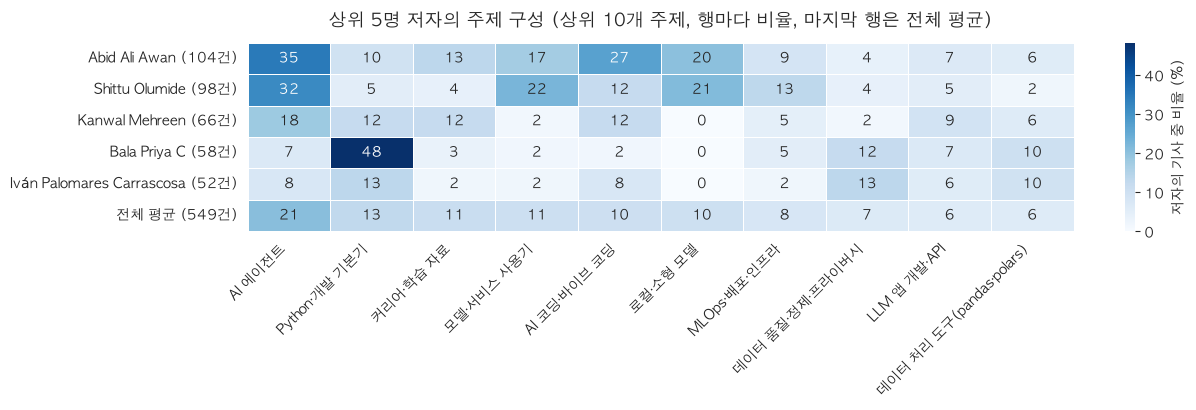

In [30]:
top_authors = author_counts.head(5).index
TOP_THEMES = THEME_ORDER[:10]
author_theme = (
    df[df["author"].isin(top_authors)]
    .groupby("author")[TOP_THEMES].mean().mul(100)
    .loc[top_authors]
)
author_theme.loc["전체 평균"] = df[TOP_THEMES].mean() * 100
# 행 이름에 기사 수를 붙여, 기사가 적은 저자의 비율은 조심해서 읽도록
author_theme.index = [f"{a} ({author_counts[a]}건)" for a in top_authors] + [f"전체 평균 ({len(df)}건)"]

fig, ax = plt.subplots(figsize=(13, 4.2))
sns.heatmap(author_theme, annot=True, fmt=".0f", cmap="Blues", linewidths=0.5,
            cbar_kws={"label": "저자의 기사 중 비율 (%)"}, ax=ax)
ax.set_title("상위 5명 저자의 주제 구성 (상위 10개 주제, 행마다 비율, 마지막 행은 전체 평균)", fontsize=13, pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**읽는 법:** 각 행을 "전체 평균" 행과 비교합니다. 특정 저자의 칸이 평균보다 훨씬 진하면 그 주제는 그 저자가 많이 쓴 주제입니다. 기사가 적은 저자는 한 건의 비중이 커서 비율이 크게 나오기 쉬우니, 행 이름의 기사 수를 함께 보세요.

### 8.2 주제 변화는 저자 구성 때문인가?

후반에 특정 주제를 많이 쓰는 저자의 글이 늘었다면, 저자들의 관심은 그대로인데 주제 비중만 바뀐 것처럼 보일 수 있습니다.
이를 확인하려고 **"저자마다 전반과 같은 비율로 주제를 썼고, 저자 구성만 후반처럼 바뀌었다면"** 후반 비중이 얼마였을지 계산합니다.

- 이 값이 후반 실제 값에 가까우면 → 변화는 대부분 저자 구성 때문
- 이 값이 전반 값에 가까우면 → 저자 구성과 상관없이 저자들이 실제로 그 주제를 더(덜) 쓴 것

In [31]:
first, second = df[df["half"] == HALVES[0]], df[df["half"] == HALVES[1]]

rows = {}
for theme in RISING + FALLING:
    rate_by_author = first.groupby("author")[theme].mean()
    # 전반에 글이 없던 저자는 전반 전체 평균 비율을 사용
    expected = second["author"].map(rate_by_author).fillna(first[theme].mean()).mean()
    rows[theme] = {
        "전반 실제(%)": first[theme].mean() * 100,
        "저자 구성만 바뀌었다면(%)": expected * 100,
        "후반 실제(%)": second[theme].mean() * 100,
    }
author_mix = pd.DataFrame(rows).T
author_mix = author_mix.round(1)

new_authors = set(second["author"]) - set(first["author"])
print(f"후반에 새로 등장한 저자: {len(new_authors)}명, 이들이 쓴 기사 {second['author'].isin(new_authors).sum()}건")
author_mix

후반에 새로 등장한 저자: 5명, 이들이 쓴 기사 14건


,전반 실제(%),저자 구성만 바뀌었다면(%),후반 실제(%)
AI 에이전트,15.3,18.9,25.9
추론 효율·비용,2.2,2.3,9.5
로컬·소형 모델,6.5,7.2,13.9
모델·서비스 사용기,7.6,10.2,13.9
업무 자동화 도구,3.6,8.1,0.7


**읽는 법:** 가운데 열("저자 구성만 바뀌었다면")이 왼쪽(전반 실제)에 가까우면, 저자 구성은 거의 영향이 없었고 저자들이 실제로 그 주제를 더(덜) 쓴 것입니다. 오른쪽(후반 실제)에 가까우면 그 주제를 많이 쓰는 저자의 글이 늘어서 생긴 변화입니다. 변화 폭이 작은 주제는 몇 건 차이로 결과가 뒤집힐 수 있으니 조심해서 읽으세요.

### 8.3 주제 간 동시 출현

한 기사에 두 주제가 함께 분류된 횟수입니다. 다만 **큰 주제끼리는 우연히도 자주 겹칩니다.** 그래서 건수와 함께, 두 주제가 서로 무관할 때 우연히 겹칠 기대값 대비 몇 배인지(**lift**)를 계산합니다. lift가 1보다 크게 높을수록 함께 이야기되는 경향이 강한 쌍입니다. 건수가 적으면 lift가 크게 튀어서(예: 강좌 목록 글 몇 개에 RAG와 파인튜닝이 나란히 나오는 경우) 8건 이상 함께 나온 쌍만 봅니다.

주의할 점도 있습니다. "coding agent"처럼 한 표현이 두 규칙(AI 코딩, AI 에이전트)에 동시에 걸리는 경우가 있어서, 이런 쌍의 lift는 규칙 구조 때문에 일부 부풀려집니다.

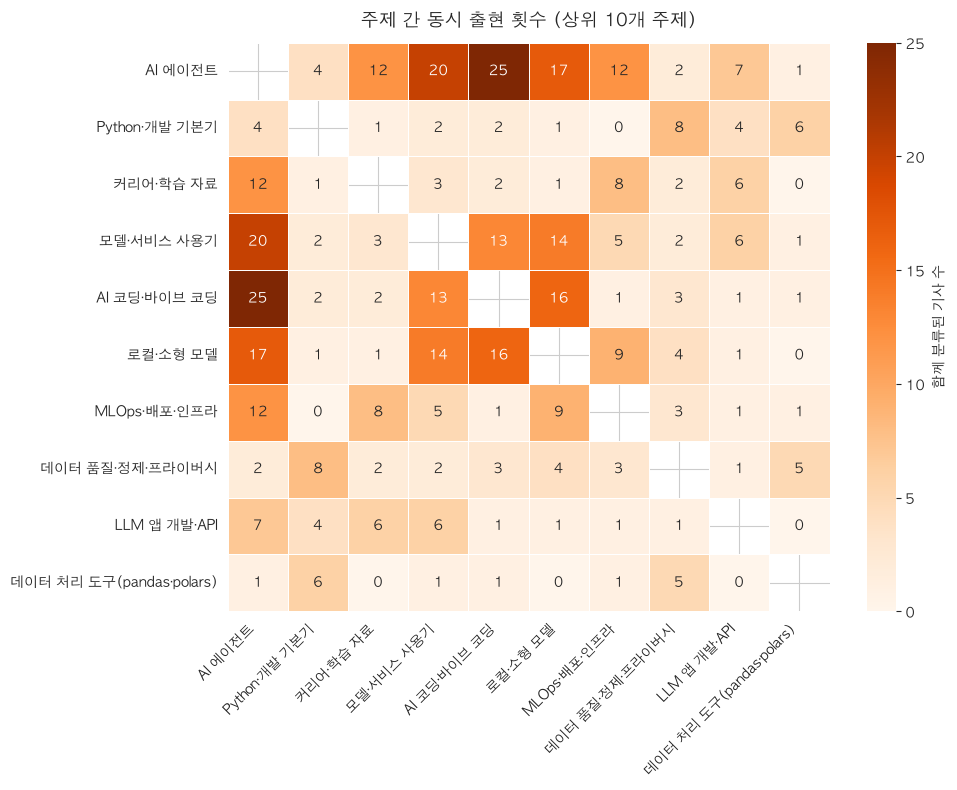

함께 분류된 기사 수  우연히 겹칠 기대값  lift(배)
로컬·소형 모델      추론 효율·비용                  11         3.3      3.4
AI 에이전트       MCP·도구 호출                  8         2.9      2.8
AI 코딩·바이브 코딩  로컬·소형 모델                  16         5.8      2.8
              추론 효율·비용                   9         3.3      2.7
로컬·소형 모델      멀티모달(음성·이미지·영상)            8         3.1      2.6
모델·서비스 사용기    로컬·소형 모델                  14         6.0      2.3
AI 에이전트       AI 코딩·바이브 코딩              25        11.7      2.1
모델·서비스 사용기    AI 코딩·바이브 코딩              13         6.1      2.1
로컬·소형 모델      MLOps·배포·인프라               9         4.4      2.1
Python·개발 기본기 데이터 품질·정제·프라이버시            8         4.7      1.7

In [32]:
CO_THEMES = THEME_ORDER[:10]   # 히트맵은 상위 10개 주제만
X = df[CO_THEMES].astype(int)
co = X.T @ X

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(co, mask=np.eye(len(co), dtype=bool), annot=True, fmt="d", cmap="Oranges",
            linewidths=0.5, cbar_kws={"label": "함께 분류된 기사 수"}, ax=ax)
ax.set_title("주제 간 동시 출현 횟수 (상위 10개 주제)", fontsize=13, pad=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 전체 주제 쌍의 lift: 실제 동시 출현 수 ÷ 우연히 겹칠 기대값
X_all = df[THEME_ORDER].astype(int)
co_all = X_all.T @ X_all
upper = np.triu(np.ones(co_all.shape, dtype=bool), k=1)
pairs = co_all.where(upper).stack().dropna().astype(int).rename("함께 분류된 기사 수").to_frame()
sizes = X_all.sum()
pairs["우연히 겹칠 기대값"] = [sizes[a] * sizes[b] / len(df) for a, b in pairs.index]
pairs["lift(배)"] = pairs["함께 분류된 기사 수"] / pairs["우연히 겹칠 기대값"]

# 건수가 적은 쌍은 lift가 크게 튀므로 MIN_PAIR_N건 이상만
MIN_PAIR_N = 8
top_pairs = pairs[pairs["함께 분류된 기사 수"] >= MIN_PAIR_N].sort_values("lift(배)", ascending=False).head(10).round(1)
top_pairs

**읽는 법:** lift가 높은 쌍은 한 기사에서 함께 다뤄지는 경향이 강한 주제입니다. 예를 들어 "로컬·소형 모델"과 "추론 효율·비용"의 lift가 높다면, 로컬 모델이 "비용을 줄이는 방법"이라는 맥락에서 이야기되고 있다고 해석할 수 있습니다.

# 9. 결론과 한계

### 9.1 이번 실행의 핵심 결과 (자동 요약)

아래 내용은 코드가 이번 실행 결과로 계산한 것이므로, 언제 실행해도 그 시점의 데이터에 맞게 바뀝니다.

In [33]:
top3_themes = theme_summary.head(3)
top_kw = [w for w, _ in word_counts.most_common() if w != "ai"][:5]
judged = half_theme[half_theme["판정"] != "-"]
best_pair = top_pairs.index[0]


def fmt_change(df_part):
    return ", ".join(f"{t}({r['변화(%p)']:+.1f}%p)" for t, r in df_part.iterrows()) or "없음"


summary_lines = [
    f"분석 대상: {len(df)}건, {PERIOD} (KST), {SOURCE}로 수집, 협찬 글 {'제외' if EXCLUDE_PARTNERS else '포함'}",
    "영역 비중 (첫 분기 → 마지막 분기): " + ", ".join(
        f"{d} {domain_q[d].iloc[0]:.0f}% → {domain_q[d].iloc[-1]:.0f}%" for d in DOMAINS),
    "주제 상위 3개: " + ", ".join(f"{t} {r['비중(%)']}%({int(r['기사 수'])}건)" for t, r in top3_themes.iterrows()),
    "제목 키워드 상위 5개(ai 제외): " + ", ".join(f"{w}({word_counts[w]})" for w in top_kw),
    "후반에 늘어난 주제: " + fmt_change(judged[judged["판정"] == "증가"].iloc[::-1]),
    "후반에 줄어든 주제: " + fmt_change(judged[judged["판정"] == "감소"]),
    f"가장 강하게 함께 다뤄진 주제: {best_pair[0]} + {best_pair[1]} "
    f"({top_pairs.iloc[0]['함께 분류된 기사 수']:.0f}건, 우연 대비 {top_pairs.iloc[0]['lift(배)']}배)",
    f"상위 3명 저자 비중: {top3_share:.0%}",
]
for line in summary_lines:
    print("•", line)

• 분석 대상: 549건, 2025.10.29~2026.10.28 (KST), REST API로 수집, 협찬 글 제외
• 영역 비중 (첫 분기 → 마지막 분기): 생성형 AI 34% → 67%, 데이터 24% → 15%, ML·운영 17% → 13%, 개발 기본기·커리어 31% → 27%
• 주제 상위 3개: AI 에이전트 20.6%(113건), Python·개발 기본기 12.9%(71건), 커리어·학습 자료 11.5%(63건)
• 제목 키워드 상위 5개(ai 제외): data(94), python(93), agent(76), build(57), model(54)
• 후반에 늘어난 주제: AI 에이전트(+10.6%p), 추론 효율·비용(+7.3%p), 로컬·소형 모델(+7.3%p), 모델·서비스 사용기(+6.2%p), 파인튜닝·모델 학습(+2.6%p)
• 후반에 줄어든 주제: 업무 자동화 도구(-2.9%p)
• 가장 강하게 함께 다뤄진 주제: 로컬·소형 모델 + 추론 효율·비용 (11건, 우연 대비 3.4배)
• 상위 3명 저자 비중: 49%


### 9.2 해석 (2026-10-29 실행 기준)

> 아래는 2026-10-29에 실행한 결과(협찬 글 49건을 뺀 549건, 2025.10.29~2026.10.28)를 보고 쓴 해석입니다. 같은 숫자를 재현하려면 0.2의 `LOAD_CSV`에 `kdnuggets_articles_365d_20261029.csv`를 지정하세요. 다른 날짜에 새로 수집하면 숫자와 순위가 달라질 수 있으니 9.1의 자동 요약과 함께 보세요.

**1. 1년 사이 콘텐츠의 무게중심이 생성형 AI로 옮겨갔다.**
생성형 AI 영역의 주제가 하나라도 걸린 기사는 분기별로 34% → 56% → 55% → 67%로 늘었고, 전반 127건에서 후반 167건으로(+14.8%p, p=0.001) 네 영역 중 유일하게 뚜렷하게 변했습니다(7.1).
반면 데이터(66건 → 57건, p=0.37)와 ML·운영(42건 → 34건, p=0.33)은 조금 줄었지만 우연과 구분되지 않습니다. 그래서 "데이터 주제가 줄었다"고 말하기는 어렵습니다. 다만 데이터 영역은 마지막 분기에 15%로 1년 중 가장 낮았고, 제목에 data가 들어간 기사도 전반 60건에서 후반 34건으로 줄어서(7.5), 데이터 쪽 비중은 지켜볼 신호입니다.

**2. AI 에이전트가 1년 내내 가장 크게 성장한 주제다.**
전체 1위(113건, 20.6%)이면서, 분기 비중이 7.6% → 21.8% → 24.1% → 28.0%로 꾸준히 올랐습니다(42건 → 71건, p=0.002). 규칙 없이 센 제목 키워드에서도 agent가 28건에서 48건으로 가장 많이 늘어서, 두 방법이 같은 결론을 가리킵니다.
저자 구성 변화만으로는 15.3%에서 18.9%까지만 설명되고 실제로는 25.9%여서(8.2), 증가의 대부분은 저자들이 실제로 에이전트 글을 더 쓴 결과입니다.
월별로 보면 7~8월에 정점(월 기사의 약 40%)을 찍은 뒤 9~10월에는 23% 정도로 내려왔습니다. 이 때문에 6~10월만 잘라 보면 "에이전트가 줄었다"는 정반대의 결론이 나옵니다. 짧은 기간의 비교만으로 트렌드를 말하면 안 되는 이유입니다.

**3. "싸고 가볍게 돌리기"가 두 번째로 뚜렷한 흐름이다.**
추론 효율·비용은 분기 비중이 2.3% → 2.1% → 7.5% → 11.2%(6건 → 26건, p<0.001), 로컬·소형 모델은 4.6% → 8.5% → 15.8% → 11.9%(18건 → 38건, p=0.005)로 늘었습니다. 두 주제는 우연히 겹칠 때보다 3.4배 자주 한 기사에 함께 나와서(8.3) 가장 강하게 묶인 쌍이고, 로컬 모델은 AI 코딩과도 2.8배 자주 함께 나옵니다(로컬 모델로 코딩 에이전트 돌리기).
두 주제 모두 저자 구성으로는 거의 설명되지 않아서(8.2), 매체 사정보다는 실제 관심 변화로 볼 수 있습니다.

**4. 식은 주제: 노코드 업무 자동화와 "바이브 코딩"이라는 유행어**
n8n·Zapier·Make·Google Opal 같은 업무 자동화 도구 글은 첫 분기 6.9%에서 이후 1% 미만으로 사라졌습니다(10건 → 2건). 저자 구성대로라면 오히려 늘었어야 해서(8.2), 관심이 실제로 옮겨간 것으로 보입니다.
제목 키워드에서는 vibe(10건 → 2건)와 docker(12건 → 2건)가 크게 줄었습니다. 다만 AI 코딩 주제 전체는 30건에서 27건으로 그대로여서, 식은 것은 AI 코딩이 아니라 "바이브 코딩"이라는 표현입니다.

**5. 해석에 주의할 결과**
- **모델·서비스 사용기 증가(+6.2%p):** 꾸준히 오른 것이 아니라 마지막 분기에만 18.9%로 뛰었습니다(앞 세 분기는 6~10%). 이 시기에 Claude Opus/Haiku 5.5, Gemini Omni, DeepSeek-V4.1 같은 모델 출시가 몰렸고, 마지막 분기 27건 중 10건을 한 저자(Shittu Olumide)가 썼습니다. 저자 구성이 증가분의 일부를 설명하므로(7.6% → 10.2%), 트렌드라기보다 출시 시기의 영향으로 봅니다.
- **파인튜닝 증가(3건 → 10건):** p=0.049로 경계선이고, 후반 10건 중 5건이 요약문에 fine-tuning이 언급된 강좌·도서 목록 글이라 트렌드로 보기 어렵습니다.
- **전체 2·3위가 기술이 아닌 글 형식:** Python·개발 기본기(2위)는 한 저자(Bala Priya C)의 글 절반 가까이가 이 주제일 만큼 특정 저자의 연재 성격이 강하고, 커리어·학습 자료(3위)는 기술 주제가 아니라 글의 형식입니다. 기술 트렌드로는 생성형 AI·데이터·ML·운영 영역의 주제를 중심으로 읽어야 합니다.

**한 줄 요약:** 지난 1년 KDnuggets의 AI·데이터 콘텐츠는 생성형 AI, 특히 **에이전트**와 **로컬·저비용 실행** 쪽으로 이동했고, 데이터·ML 기본기 주제는 비중이 줄었다고 단정할 수는 없지만 존재감이 상대적으로 작아졌습니다.

### 9.3 분석의 한계

1. **한 매체의 시각입니다.** KDnuggets는 실무 튜토리얼 중심 매체이고, 저자 19명 중 상위 3명이 기사의 절반 가까이를 씁니다(4.2절). 저자 구성 효과를 8.2절에서 따로 확인했지만, 매체의 편집 방향 자체는 걸러낼 수 없습니다. Towards Data Science, Hugging Face 블로그처럼 다른 소스와 교차 확인하면 "업계 흐름"에 더 가까워집니다.
2. **1년은 4개 분기뿐입니다.** 계절성(연말·연초 회고 글 등)과 장기 추세를 구분하기에는 짧습니다. `PERIOD_DAYS`를 730으로 늘리면 2년치로 비교할 수 있습니다.
3. **주제 규칙은 이번 데이터에 맞춰 만들었습니다.** 1년치 제목을 보고 만들고 다듬은 규칙이라, 다른 시기에는 새로 등장한 도구나 용어를 놓칠 수 있습니다. 주제가 하나도 안 걸린 기사가 약 10%이고, 6장의 단어 빈도로 이를 보완했습니다. 정규표현식이라 문맥을 이해하지 못한다는 한계도 그대로입니다.
4. **여러 주제를 한꺼번에 검정했습니다.** 주제 23개를 비교하면 실제 변화가 없어도 1개 정도는 우연히 p<0.05가 나올 수 있습니다. 그래서 p값과 분기 흐름이 함께 맞는 결과(에이전트, 추론 효율·비용, 로컬 모델)만 결론의 중심에 두었습니다.
5. **관심도를 반영하지 않습니다.** 기사 수는 "얼마나 많이 썼는가"이지 "얼마나 많이 읽혔는가"가 아닙니다. 조회수나 공유 수가 없어서 실제 독자 반응과는 차이가 있을 수 있습니다.
6. **실행 시점마다 결과가 다릅니다.** 항상 최신 1년을 수집하므로 9.2의 해석은 작성 시점 기준이며, 같은 결과는 저장한 CSV(`LOAD_CSV`)로 재현합니다.